In [1]:
import numpy as np
import batoid
import matplotlib.pyplot as plt
import math
from scipy.special import jv
from scipy.special import j1

In [2]:
def telescopeCreation(WL,pdx,pdy,pdz,ptx,pty,sdx,sdy,sdz,stx,sty):
    #gaberration inputs in microns and arcseconds
    global telescope, M1

    global outter1, inner1, outterD
    
    K = 1000000 #meter to micron conversion
    A = 3600 #degree to arcsec conversion
    
    R1, conic1, inner1, outter1 = -16.256, -0.9953569, 1.38, 6.42
    #M1coord = defineCoordinate(anglX=0.0035, anglY=0.0035, anglZ=0, posX=200e-6, posY=200e-6, posZ=200e-6).local()
    M1coord = defineCoordinate(posX=pdx/K, posY=pdy/K, posZ=pdz/K, anglX=ptx/A, anglY=pty/A).local()
    M1 = optic('M1',type='Quadric', RoC=R1, conic=conic1, inDiam=inner1, outDiam=outter1, coordSys=M1coord).mirrorWithSpider(width=0.3, height=4)
                                                                                                                             
    R2, conic2, outter2 = -1.660575, -1.566503, 0.7147252
    #M2coord = defineCoordinate(anglX=-0.00878, anglY=0.0116, anglZ=0, posX=-0.2014e-3, posY=0.8984e-3, posZ=-7.400+191.3e-6).local()
    M2coord = defineCoordinate(posX=sdx/K, posY=sdy/K, posZ=-7.400+(sdz/K), anglX=stx/A, anglY=sty/A).local()
    M2 = optic('M2', type='Quadric', RoC=R2, conic=conic2, outDiam=outter2, coordSys=M2coord).mirror()

    R3, conic3, outter3 = -1.830517, -0.718069, 0.920733
    M3coord = defineCoordinate(posZ=+0.050).local()
    M3 = optic('M3', type='Quadric', RoC=R3, conic=conic3, outDiam=outter3, coordSys=M3coord).mirror()

    outter4 = 0.0991468
    M4coord = defineCoordinate(posZ=-0.983629).local()
    M4 = optic('M4', outDiam=outter4, coordSys=M4coord).flatMirror()

    outterD = 0.9
    Dcoord = defineCoordinate(posZ=0.237581).local()
    D = optic('D', outDiam=outterD, coordSys=Dcoord).detector()

    telescope = build.compoundOptic(M1, M2, M3, M4, D, 
                                    pupilSize=6.46, backDist=7.5,
                                    EPcoord=defineCoordinate(posZ=0).local())
    
    return telescope

In [3]:
%run Batoid4LOFT.ipynb

In [373]:
poke = 0.000003

In [ ]:
def bessel2d(n, npix=100, rho=None, **kwargs):
    if rho is None:
        x = (np.arange(npix, dtype=np.float64) - (npix - 1) / 2.) / ((npix - 1) / 16.)
        y = x
        xx, yy = np.meshgrid(x, y)

        rho = np.sqrt(xx ** 2 + yy ** 2)

    result = jv(n, 2*np.pi*rho)*(1/(np.pi*rho))

    return result

In [4]:
def _is_odd(integer):
    """Helper for testing if an integer is odd by bitwise & with 1."""
    return integer & 1

def noll_indices(j):
    """Convert from 1-D to 2-D indexing for Zernikes or Hexikes.

    Parameters
    ----------
    j : int
        Zernike function ordinate, following the convention of Noll et al. JOSA 1976.
        Starts at 1.

    """
    if j < 1:
        raise ValueError("Zernike index j must be a positive integer.")

    # from i, compute m and n
    # I'm not sure if there is an easier/cleaner algorithm or not.
    # This seems semi-complicated to me...

    # figure out which row of the triangle we're in (easy):
    n = int(np.ceil((-1 + np.sqrt(1 + 8 * j)) / 2) - 1)
    if n == 0:
        m = 0
    else:
        nprev = (n + 1) * (n + 2) / 2  # figure out which entry in the row (harder)
        # The rule is that the even Z obtain even indices j, the odd Z odd indices j.
        # Within a given n, lower values of m obtain lower j.

        resid = int(j - nprev - 1)

        if _is_odd(j):
            sign = -1
        else:
            sign = 1

        if _is_odd(n):
            row_m = [1, 1]
        else:
            row_m = [0]

        for i in range(int(np.floor(n / 2.))):
            row_m.append(row_m[-1] + 2)
            row_m.append(row_m[-1])

        m = row_m[resid] * sign

    return n, m

def circ_bessel(n, m, npix=128, rho=None, theta=None, outside=np.nan, zero=19.053609871416903, **kwargs):
    """Return the Circular Bessel function for a given pupil.

    For this function the desired Circular Bessel function is specified by 2 indices m and n.
    See circ_bessel1 for an equivalent function in which the polynomials are
    ordered by a single index.

    You may specify the pupil in one of two ways:

        circ_bessel(n, m, npix)
            where npix specifies a pupil diameter in pixels.
            The returned pupil will be a circular aperture
            with this diameter, embedded in a square array
            of size npix*npix.

        circ_bessel(n, m, rho=r, theta=theta)
            Which explicitly provides the desired pupil coordinates
            as arrays r and theta. These need not be regular or contiguous.

    Parameters
    ----------
    n, m : int
        Zernike function degree
    npix : int
        Desired diameter for circular pupil. Only used if `rho` and
        `theta` are not provided.
    rho, theta : array_like
        Image plane coordinates. `rho` should be 0 at the origin
        and 1.0 at the edge of the circular pupil. `theta` should be
        the angle in radians.
    outside : float
        Value for pixels outside the circular aperture (rho > 1).
        Default is `np.nan`, but you may also find it useful for this to
        be 0.0 sometimes.

    Returns
    -------
    cb : 2D numpy array
        circ_bessel(m,n) evaluated at each (rho, theta)
    """

    if theta is None and rho is None:
        x = (np.arange(npix, dtype=np.float64) - (npix - 1) / 2.) / (zero)
        y = x
        xx, yy = np.meshgrid(x, y)

        rho = np.sqrt(xx ** 2 + yy ** 2)
        theta = np.arctan2(yy, xx)
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")
        
    if not np.all(np.asarray(rho.shape == theta.shape)):
        raise ValueError('The rho and theta arrays do not have consistent shape.')

    if m == 0:
        if n == 0:
            cb_result = j1(2*np.pi*rho) * (1/rho)
        else:
            cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho)
    elif m > 0:
        cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho) * np.cos(np.abs(m) * theta)
    else:
        cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho) * np.sin(np.abs(m) * theta)
    return cb_result


def circ_bessel1(j, **kwargs):
    """ Return the Circular Bessel function Jv_j for pupil points {r,theta}.

    Note that there are multiple contradictory conventions for labeling Zernikes
    with one single index. We follow that of Noll et al. JOSA 1976.

    Parameters
    ----------
    j : int
        Zernike function ordinate, following the convention of
        Noll et al. JOSA 1976

    Returns
    -------
    cb : 2D numpy array
        Jv_j evaluated at each (rho, theta)
    """
    n, m = noll_indices(j)
    return circ_bessel(n, m, **kwargs)

In [117]:
"""
Zernike 1-13 FT circ_bessel conversion

Z1  = circ_bessel(0,0)   = Piston
Z2  = circ_bessel(1,1)   = X tilt
Z3  = circ_bessel(1,-1)  = Y tilt
Z4  = circ_bessel(2,0)   = Defocus
Z5  = circ_bessel(2,-2)  = Oblique astigmatism
Z6  = circ_bessel(2,2)   = Vertical astigmatism
Z7  = circ_bessel(3,-1)  = Vertical coma
Z8  = circ_bessel(3,1)   = Horizontal coma 
Z9  = circ_bessel(3,-3)  = Vertical trefoil 
Z10 = circ_bessel(3,3)   = Oblique trefoil 
Z11 = circ_bessel(4,0)   = Primary spherical
Z12 = circ_bessel(4,2)   = Vertical secondary astigmatism 
Z13 = circ_bessel(4,-2)  = Oblique secondary astigmatism 
"""

'\nZernike 1-13 FT circ_bessel conversion\n\nZ1  = circ_bessel(0,0)   = Piston\nZ2  = circ_bessel(1,1)   = X tilt\nZ3  = circ_bessel(1,-1)  = Y tilt\nZ4  = circ_bessel(2,0)   = Defocus\nZ5  = circ_bessel(2,-2)  = Oblique astigmatism\nZ6  = circ_bessel(2,2)   = Vertical astigmatism\nZ7  = circ_bessel(3,-1)  = Vertical coma\nZ8  = circ_bessel(3,1)   = Horizontal coma \nZ9  = circ_bessel(3,-3)  = Vertical trefoil \nZ10 = circ_bessel(3,3)   = Oblique trefoil \nZ11 = circ_bessel(4,0)   = Primary spherical\nZ12 = circ_bessel(4,2)   = Vertical secondary astigmatism \nZ13 = circ_bessel(4,-2)  = Oblique secondary astigmatism \n'

In [5]:
ne.set_num_threads(8)

8

In [100]:
x = (np.arange(128, dtype=np.float64) - (2048 - 1) / 2.) / (19.053609871416903)
y = x
xx, yy = np.meshgrid(x, y)
rho = ne.evaluate('sqrt(xx ** 2 + yy ** 2)')
theta = ne.evaluate('arctan2(yy, xx)')
%timeit jv4 * (1/rho) * ne.evaluate('cos(abs(3) * theta)')

125 µs ± 2.78 µs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [63]:
import numexpr as ne

In [94]:
x = (np.arange(2048, dtype=np.float64) - (2048 - 1) / 2.) / (19.053609871416903)
y = x
xx, yy = np.meshgrid(x, y)
rho = np.sqrt(xx ** 2 + yy ** 2)
theta = np.arctan2(yy, xx)
%timeit jv4 * (1/rho) * np.cos(np.abs(3) * theta)

28.1 ms ± 3.75 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [87]:
x = (np.arange(2048, dtype=np.float64) - (2048 - 1) / 2.) / (19.053609871416903)
y = x
xx, yy = np.meshgrid(x, y)
rho = np.sqrt(xx ** 2 + yy ** 2)
theta = np.arctan2(yy, xx)
%timeit jv(1+3, 2*np.pi*rho)

1.06 s ± 5.55 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [99]:
jv4 = jv(1+3, 2*np.pi*rho)

In [5]:
def basis_vectors(nterms=15, npix=256, rho=None, theta=None, **kwargs):
    """
    Return a cube of Basis terms from 1 to N each as a 2D array
    showing the value at each point. Default is circular bessel

    Parameters
    ----------
    nterms : int, optional
        Number of terms to return, starting from piston.
        Default is 15.
    npix : int
        Desired pixel diameter for circular pupil. Only used if `rho`
        and `theta` are not provided.
    rho, theta : array_like
        Image plane coordinates. `rho` should be 0 at the origin
        and 1.0 at the edge of the circular pupil. `theta` should be
        the angle in radians.

    """
    if rho is not None and theta is not None:
        # both are required, but validated in zernike1
        shape = rho.shape
        use_polar = True
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")

    else:
        shape = (npix, npix)
        use_polar = False

    basis_output = np.zeros((nterms,) + shape)

    if use_polar:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, rho=rho, theta=theta, **kwargs)
    else:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, npix=npix, **kwargs)
    return basis_output

In [6]:
"""def decompose_psf(psf, nterms=15, basis=basis_vectors,
                  **kwargs):

    npix=psf.shape[0]

    basis_set = basis(
        nterms=nterms,
        npix=npix,
        outside=np.nan,
        **kwargs
    )
    #psft = np.ones((nterms,npix,npix))
    #psft = psft[:]*psf
    #td = np.tensordot(psft, basis_set, axes=([1,2],[1,2]))/np.tensordot(basis_set, basis_set, axes=([1,2],[1,2]))
    #coeffs = np.diag(td)
    coeffs = [(np.vdot(psf, b)/(np.vdot(b,b))) for b in basis_set]
    coeffs = np.array(coeffs)

    return coeffs"""

def decompose_psf(psf, nterms=15, basis=basis_vectors, **kwargs):
    npix = psf.shape[0]
    basis_set = basis(nterms=nterms, npix=npix, outside=np.nan, **kwargs)
    basis_stack = np.stack(basis_set)  # shape: (nterms, npix, npix)
    psf_flat = psf.ravel()
    basis_flat = basis_stack.reshape(nterms, -1)
    numerators = np.dot(basis_flat, psf_flat)
    #numerators = ne.evaluate('sum(basis_flat*psf_flat)')
    denominators = np.einsum('ij,ij->i', basis_flat, basis_flat)
    #denominators = ne.evaluate('sum(basis_flat*basis_flat)')
    coeffs = numerators / denominators
    return coeffs

In [53]:
import mlx.core as mx

In [ ]:
%prun 

In [56]:
def mlx_decompose_psf(psf, nterms=15, basis=basis_vectors, **kwargs):
    npix = psf.shape[0]
    psf = mx.array(psf)
    basis_set = basis(nterms=nterms, npix=npix, outside=np.nan, **kwargs)
    basis_set = mx.array(basis_set)
    basis_stack = mx.stack(basis_set)  # shape: (nterms, npix, npix)
    psf_flat = mx.flatten(psf)
    basis_flat = mx.reshape(basis_stack, (nterms, -1))
    numerators = mx.inner(basis_flat, psf_flat, stream=mx.gpu)
    #numerators = ne.evaluate('sum(basis_flat*psf_flat)')
    denominators = mx.einsum('ij,ij->i', basis_flat, basis_flat, stream=mx.gpu)
    #denominators = ne.evaluate('sum(basis_flat*basis_flat)')
    coeffs = mx.divide(numerators, denominators, stream=mx.gpu)
    return coeffs

In [15]:
np.random.normal(loc=0,scale=50,size=2)

array([20.39358778,  8.67781027])

In [7]:
def genpsf(WL=650e-9, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, sdx=0, sdy=0, sdz=0, stx=0, sty=0, dterms=5):

    telescope = telescopeCreation(WL,pdx, pdy, pdz, ptx, pty, sdx, sdy, sdz, stx, sty)
    infoTelescope = details(telescope, fieldX=0, fieldY=0.17, wavelength=WL)
    PSF, _ = infoTelescope.fftPSF(npx=16, pad=2)
    r = decompose_psf(PSF, nterms=dterms, basis=basis_vectors)

    return r

In [9]:
vec_genpsf = np.frompyfunc(genpsf, 12, 1)

In [9]:
#Vary pdx 
lpx = np.arange(20.394-20, 20.394+21, 1)
%prun ars = vec_genpsf(650e-9, lpx, 8.678, 0, 0, 0, 0, 0, 0, 0, 0, 5)
ars = np.array(ars.tolist()).T
arsny = vec_genpsf(650e-9, lpx, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5)
arsny = np.array(arsny.tolist()).T

         175871 function calls (175830 primitive calls) in 2.990 seconds

   Ordered by: internal time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      820    0.936    0.001    0.936    0.001 {built-in method batoid._batoid.reflect}
      820    0.291    0.000    0.291    0.000 {built-in method batoid._batoid.obscure}
      287    0.208    0.001    0.208    0.001 {built-in method batoid._batoid.intersect}
      615    0.128    0.000    0.128    0.000 numeric.py:401(full_like)
      656    0.124    0.000    0.124    0.000 {method 'copy' of 'numpy.ndarray' objects}
       41    0.122    0.003    2.313    0.056 3190696417.py:198(wavefront)
      205    0.111    0.001    0.117    0.001 702257718.py:51(circ_bessel)
       82    0.100    0.001    0.609    0.007 rayVector.py:219(asGrid)
    10578    0.096    0.000    0.096    0.000 {built-in method numpy.array}
      205    0.088    0.000    0.088    0.000 {built-in method batoid._batoid.sag}
      123    0.076  

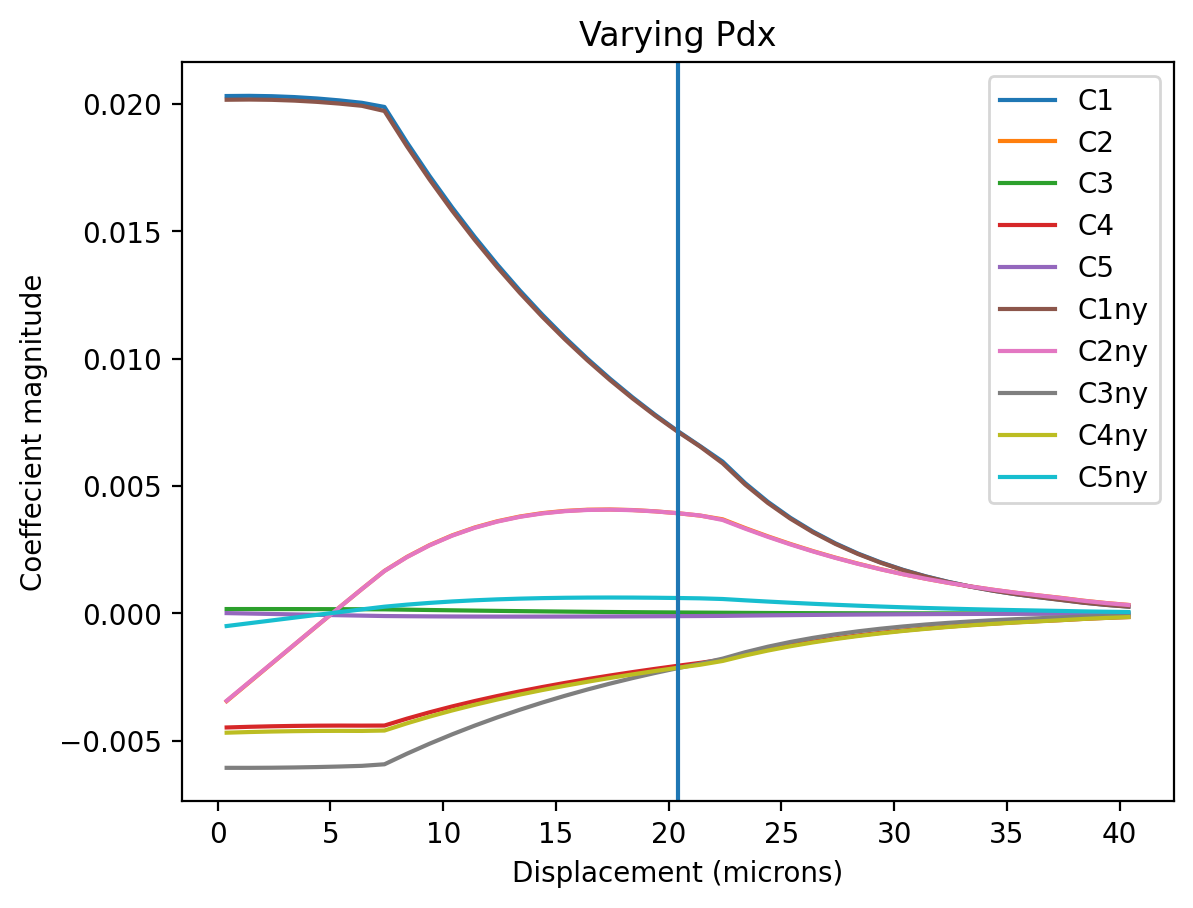

In [65]:
plt.plot(lpx, ars[0], label='C1')
plt.plot(lpx, ars[1], label='C2')
plt.plot(lpx, ars[2], label='C3')
plt.plot(lpx, ars[3], label='C4')
plt.plot(lpx, ars[4], label='C5')
plt.plot(lpx, arsny[0], label='C1ny')
plt.plot(lpx, arsny[1], label='C2ny')
plt.plot(lpx, arsny[2], label='C3ny')
plt.plot(lpx, arsny[3], label='C4ny')
plt.plot(lpx, arsny[4], label='C5ny')
plt.title("Varying Pdx")
plt.legend()
plt.xlabel("Displacement (microns)")
plt.ylabel("Coeffecient magnitude")
plt.axvline(x=20.39358778)

In [68]:
#Vary pdx 
lpy = np.arange(8.678-75, 8.678+75, 10)
ars = vec_genpsf(650e-9, 20.394, lpy, 0, 0, 0, 0, 0, 0, 0, 0, 5)
ars = np.array(ars.tolist()).T
arsnx = vec_genpsf(650e-9, 0, lpy, 0, 0, 0, 0, 0, 0, 0, 0, 5)
arsnx = np.array(arsnx.tolist()).T

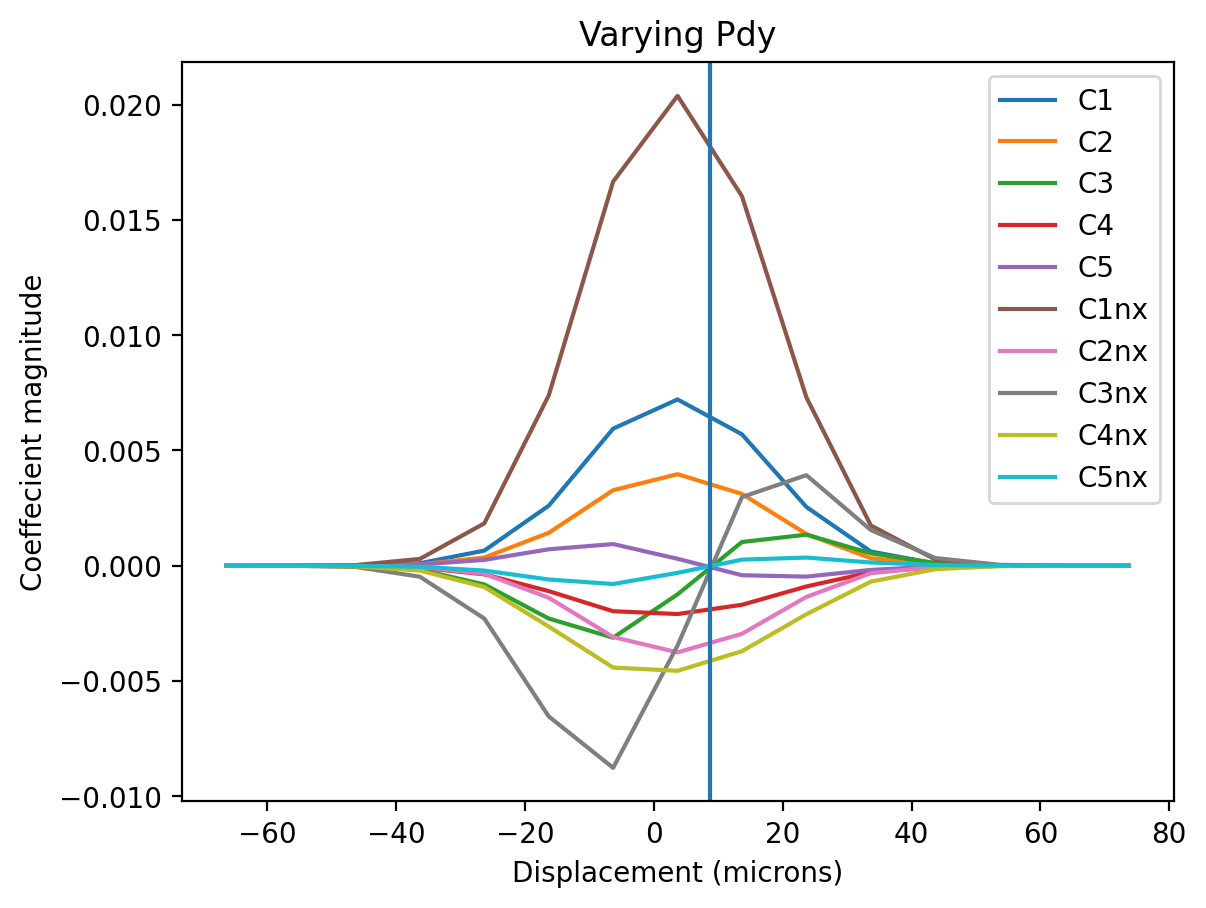

In [69]:
plt.plot(lpy, ars[0], label='C1')
plt.plot(lpy, ars[1], label='C2')
plt.plot(lpy, ars[2], label='C3')
plt.plot(lpy, ars[3], label='C4')
plt.plot(lpy, ars[4], label='C5')
plt.plot(lpy, arsnx[0], label='C1nx')
plt.plot(lpy, arsnx[1], label='C2nx')
plt.plot(lpy, arsnx[2], label='C3nx')
plt.plot(lpy, arsnx[3], label='C4nx')
plt.plot(lpy, arsnx[4], label='C5nx')
plt.title("Varying Pdy")
plt.legend()
plt.xlabel("Displacement (microns)")
plt.ylabel("Coeffecient magnitude")
plt.axvline(x=8.67781027)

In [ ]:
#Vary pdx  and pdy for c5
lpx = np.arange(20.394-8, 20.394+8, 1)
lpy = np.arange(8.678-80, 8.678+80, 10)
ars = vec_genpsf(650e-9, lpx, lpy, 0, 0, 0, 0, 0, 0, 0, 0, 5)
ars = np.array(ars.tolist()).T

Text(0, 0.5, 'Pdy (microns)')

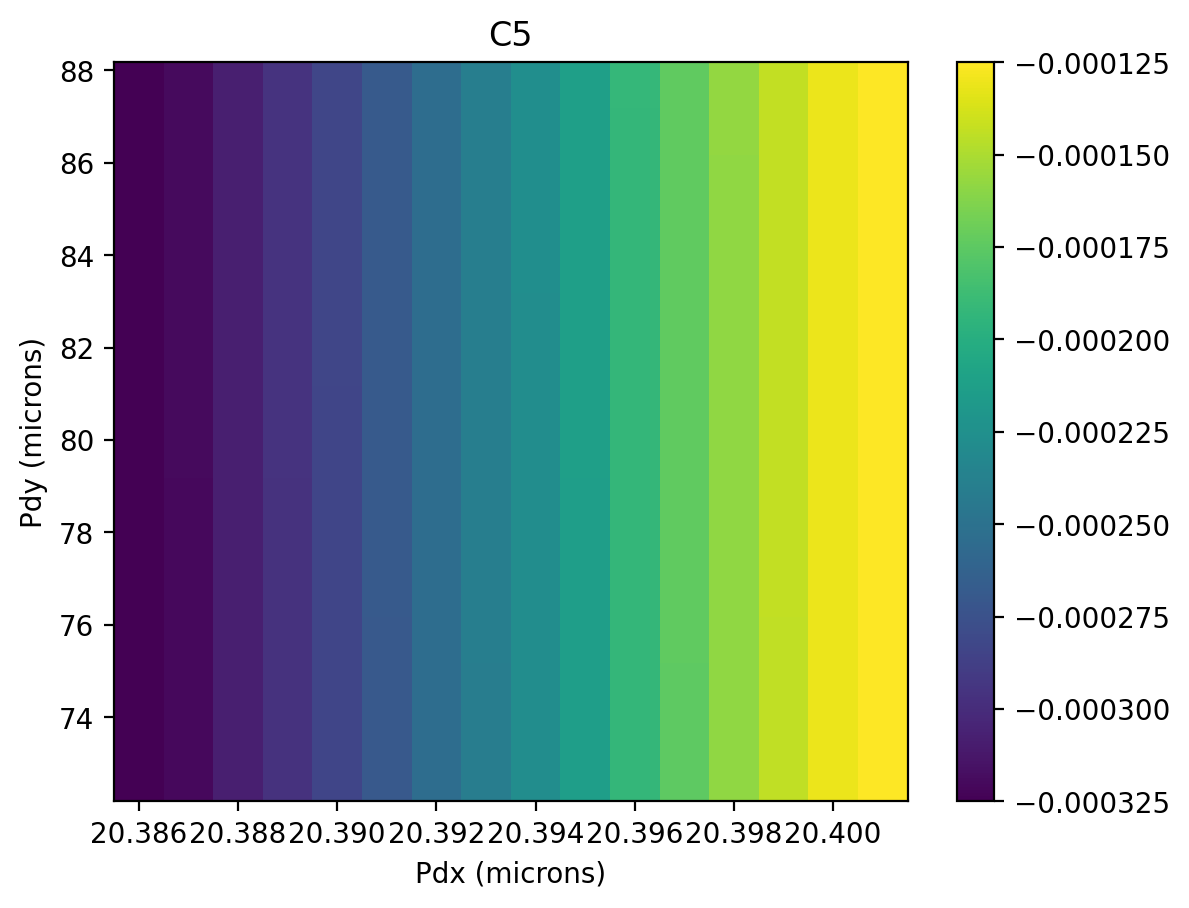

In [134]:
x = np.arange(20.394-0.008, 20.394+0.008, 0.001)
y = np.arange(80.678-8, 80.678+8, 1)
xx, yy = np.meshgrid(x, y)
vec_genpsf = np.frompyfunc(genpsf, 12, 1)
ars = vec_genpsf(650e-9, xx, yy, 0, 0, 0, 0, 0, 0, 0, 0, 5)
ars = np.array(ars.tolist()).T[4]
h = plt.pcolormesh(x,y,ars, vmin=-0.000325, vmax=-0.000125)
plt.colorbar()
plt.title("C5")
plt.xlabel("Pdx (microns)")
plt.ylabel("Pdy (microns)")

Text(0, 0.5, 'Pdy (microns)')

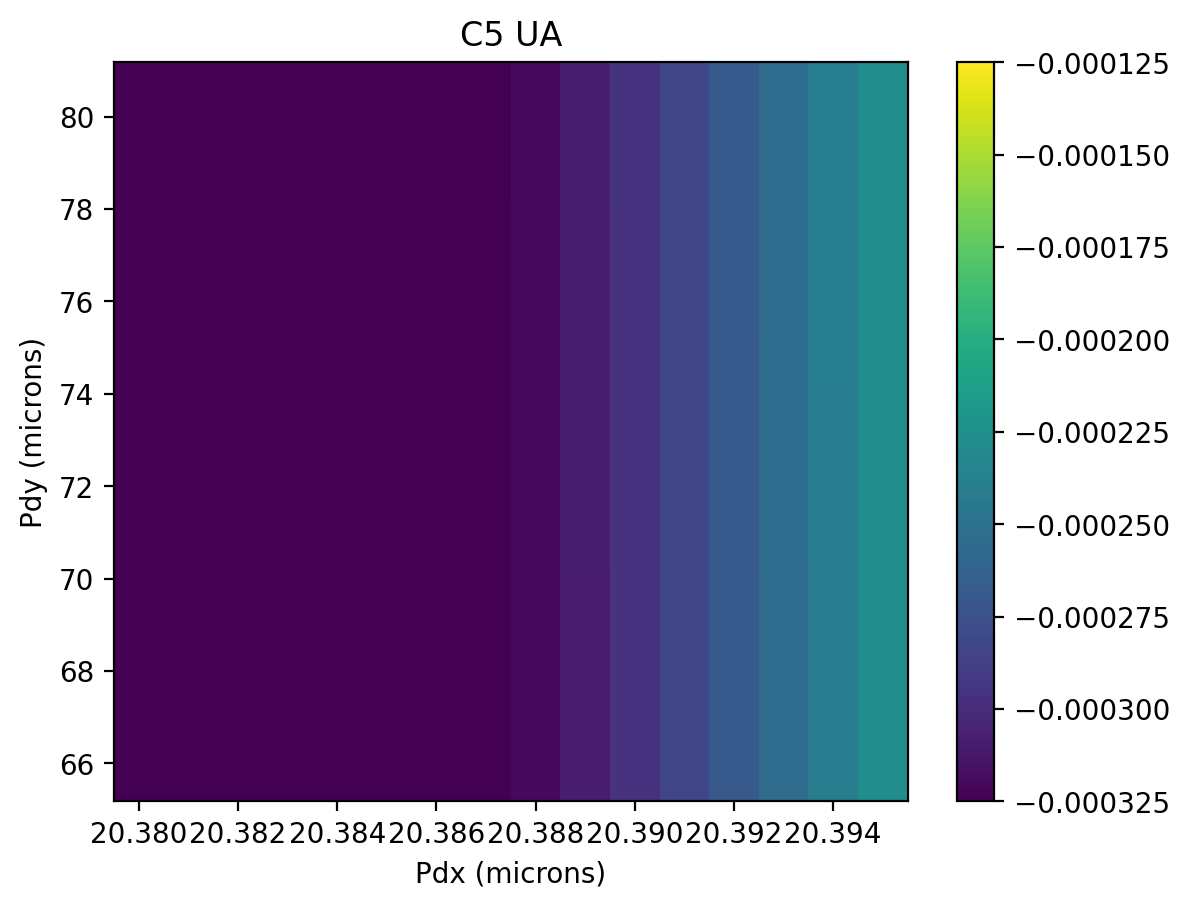

In [ ]:
#Unaberrated
x = np.arange(20.380, 20.395, 0.001)
y = np.arange(65.678, 81.678, 1)
xx, yy = np.meshgrid(x, y)
vec_genpsf = np.frompyfunc(genpsf, 12, 1)
ars = vec_genpsf(650e-9, xx, yy, 0, 0, 0, 0, 0, 0, 0, 0, 5)
ars = np.array(ars.tolist()).T[4]
h = plt.pcolormesh(x, y, ars, shading='auto',vmin=-0.000325, vmax=-0.000125)
plt.colorbar()
plt.title("C5 UA")
plt.xlabel("Pdx (microns)")
plt.ylabel("Pdy (microns)")

In [174]:
xgrad = np.gradient(ars)[0]
ygrad = np.gradient(ars)[1]

Text(0, 0.5, 'Pdy (microns)')

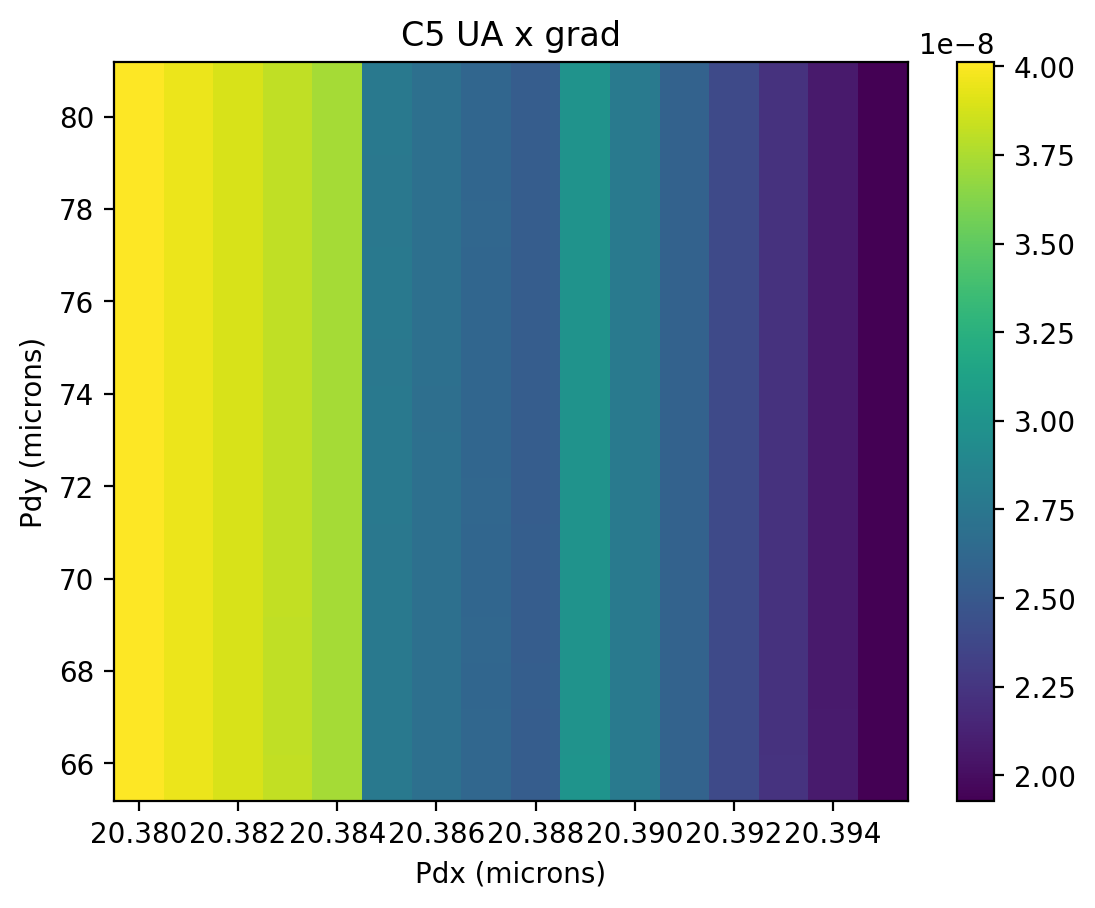

In [182]:
#X gradient
x = np.arange(20.380, 20.395, 0.001)
y = np.arange(65.678, 81.678, 1)
h = plt.pcolormesh(x, y, xgrad, shading='auto')
plt.colorbar()
plt.title("C5 UA x grad")
plt.xlabel("Pdx (microns)")
plt.ylabel("Pdy (microns)")

Text(0, 0.5, 'Pdy (microns)')

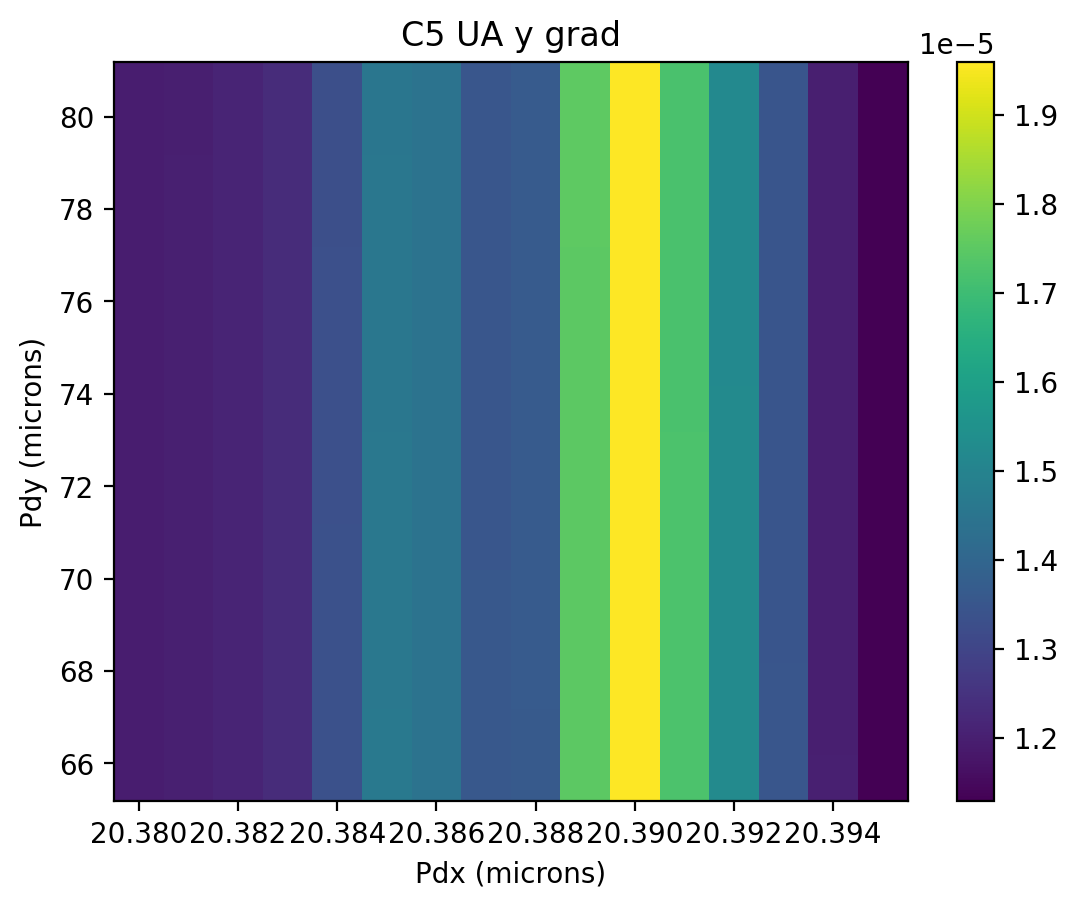

In [181]:
#Ygradient
x = np.arange(20.380, 20.395, 0.001)
y = np.arange(65.678, 81.678, 1)
h = plt.pcolormesh(x, y, ygrad, shading='auto')
plt.colorbar()
plt.title("C5 UA y grad")
plt.xlabel("Pdx (microns)")
plt.ylabel("Pdy (microns)")

In [ ]:
plt.plot(lpy, ars[0], label='C1')
plt.plot(lpy, ars[1], label='C2')
plt.plot(lpy, ars[2], label='C3')
plt.plot(lpy, ars[3], label='C4')
plt.plot(lpy, ars[4], label='C5')
plt.title("Varying Pdy")
plt.legend()
plt.xlabel("Displacement (microns)")
plt.ylabel("Coeffecient magnitude")
plt.axvline(x=8.67781027)

In [103]:
lpx = np.arange(-150, 150, 1)
ars = vec_genpsf(650e-9, lpx, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5)
ars = np.array(ars.tolist()).T

Text(0, 0.5, 'Coeffecient magnitude')

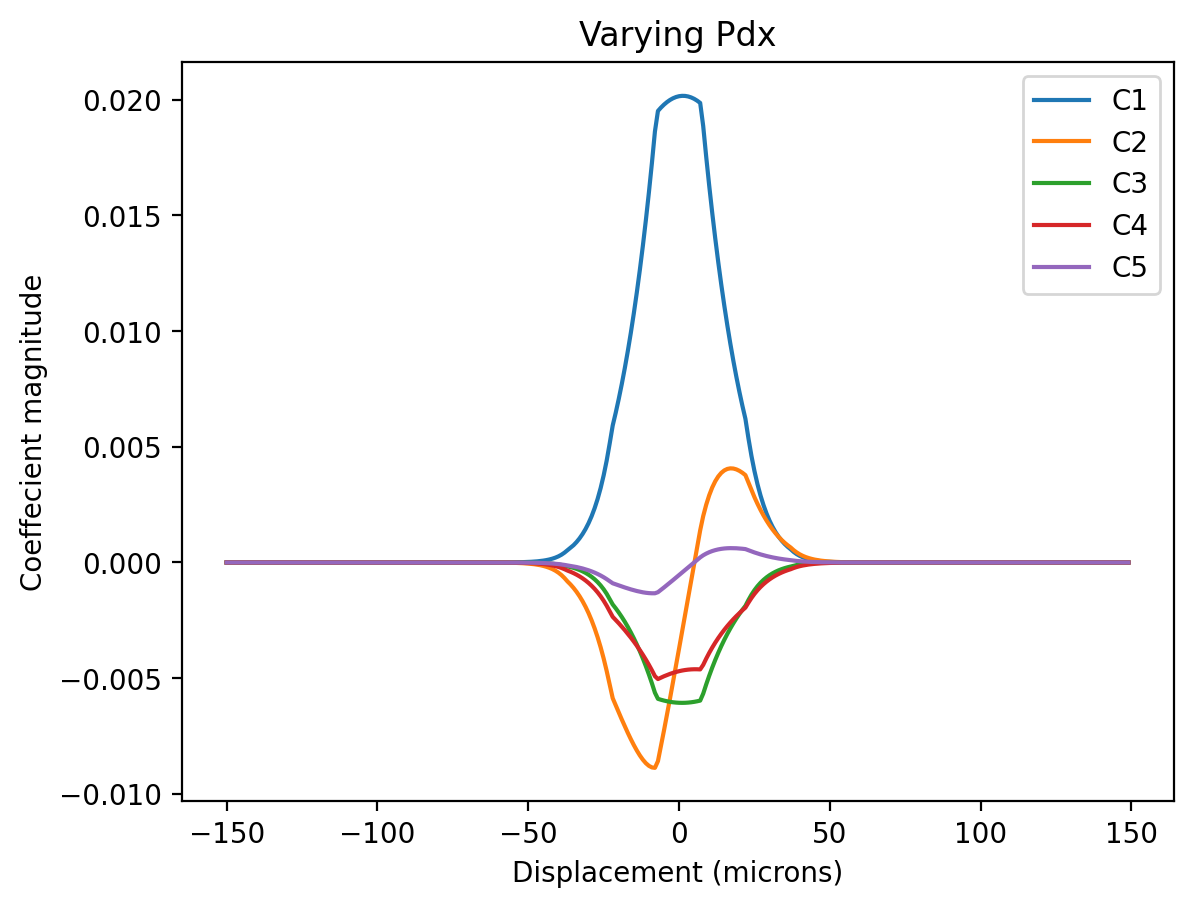

In [104]:
plt.plot(lpx, ars[0], label='C1')
plt.plot(lpx, ars[1], label='C2')
plt.plot(lpx, ars[2], label='C3')
plt.plot(lpx, ars[3], label='C4')
plt.plot(lpx, ars[4], label='C5')
plt.title("Varying Pdx")
plt.legend()
plt.xlabel("Displacement (microns)")
plt.ylabel("Coeffecient magnitude")

In [ ]:
vec_genpsf = np.frompyfunc(genpsf, 12, 1)
ars = vec_genpsf(650e-9, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5)
ars = np.array(ars.tolist()).T

Text(0, 0.5, 'Coeffecient magnitude')

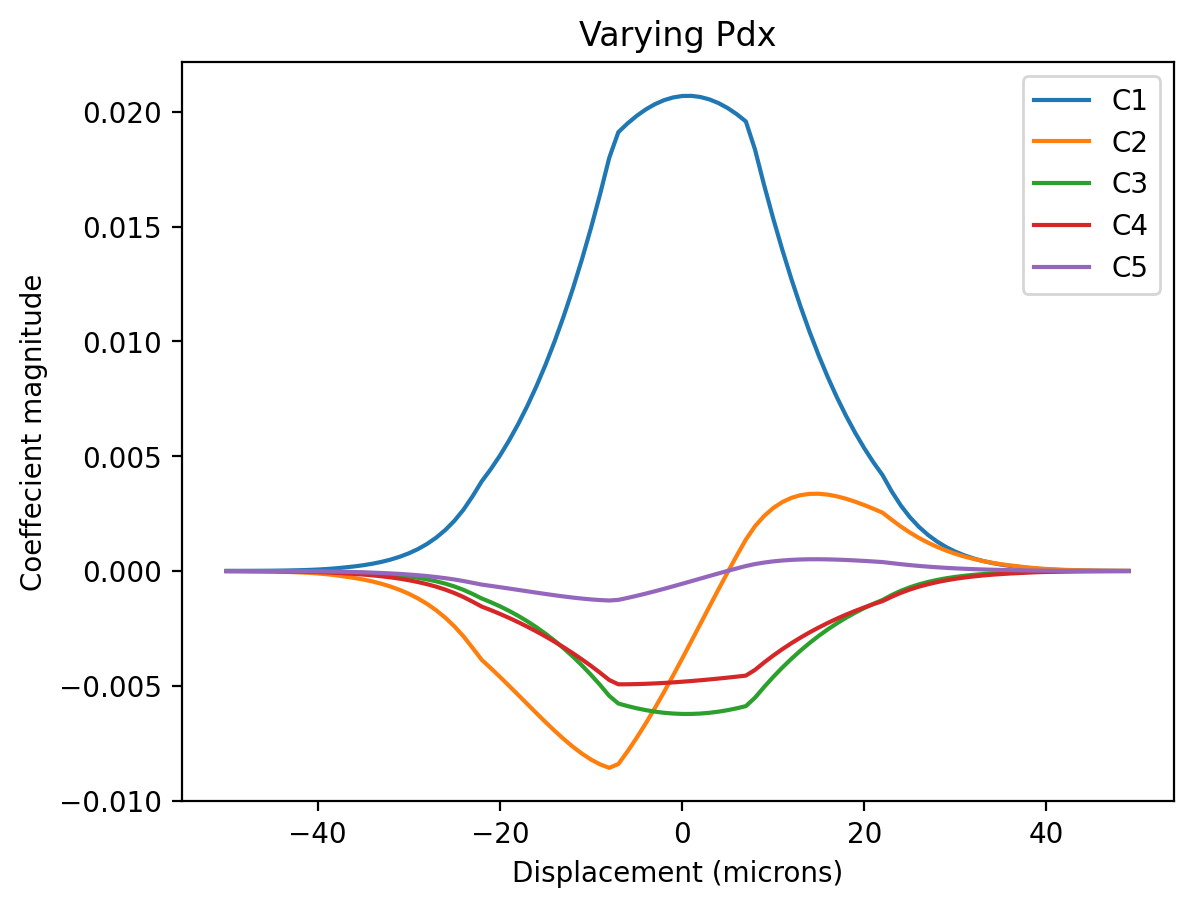

In [ ]:
plt.plot(lpx, ars[0], label='C1')
plt.plot(lpx, ars[1], label='C2')
plt.plot(lpx, ars[2], label='C3')
plt.plot(lpx, ars[3], label='C4')
plt.plot(lpx, ars[4], label='C5')
plt.title("Varying Pdx")
plt.legend()
plt.xlabel("Displacement (microns)")
plt.ylabel("Coeffecient magnitude")

In [66]:
lpx = np.arange(-60, 60, 0.1)
ars = vec_genpsf(650e-9, lpx, 0, 0, 0, 0, 0, 0, 0, 0, 0, 11)
ars = np.array(ars.tolist()).T

Text(0, 0.5, 'Coeffecient magnitude')

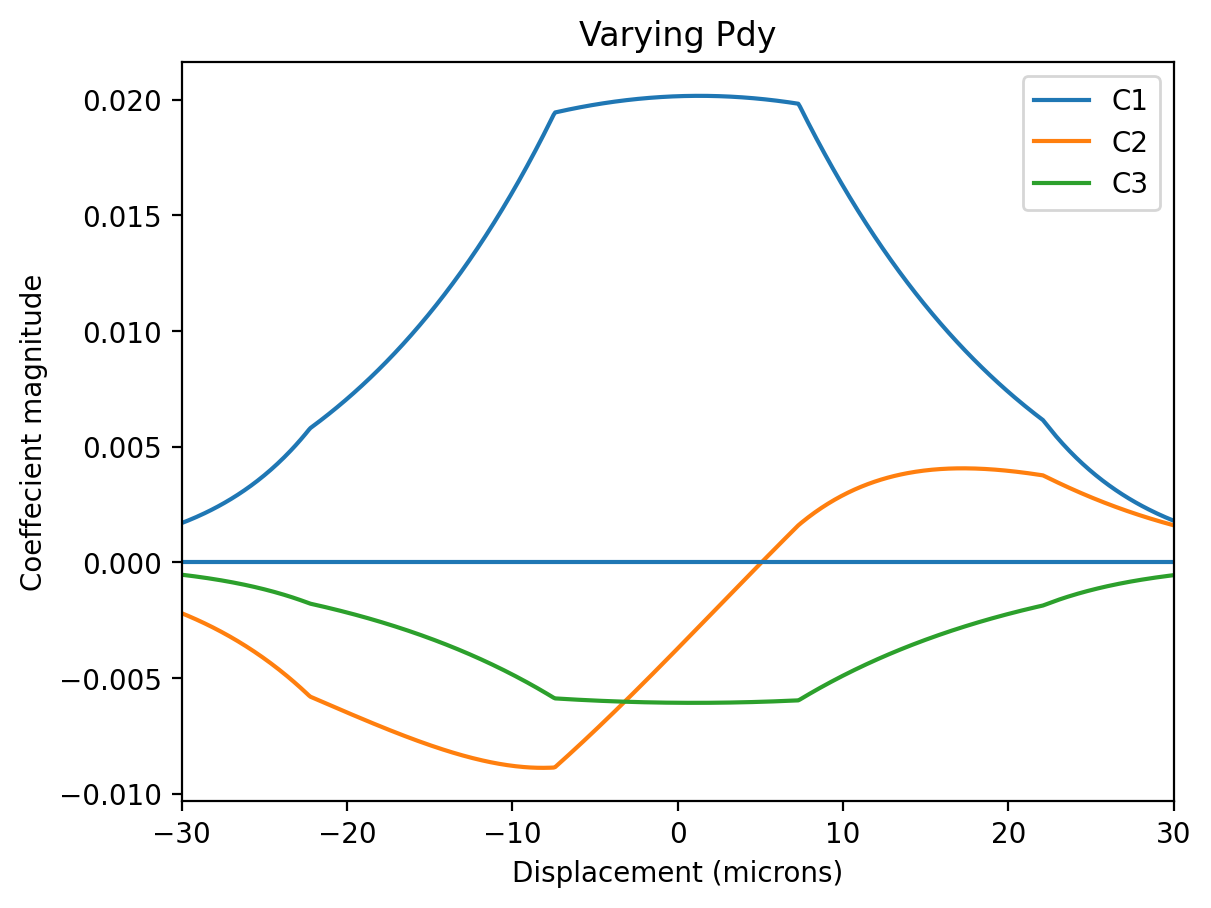

In [67]:
plt.plot(lpx, ars[0], label='C1')
plt.plot(lpx, ars[1], label='C2')
plt.plot(lpx, ars[2], label='C3')
#plt.plot(lpx, ars[3], label='C4')
#plt.plot(lpx, ars[4], label='C5')
#plt.plot(lpx, ars[5], label='C6')
#plt.plot(lpx, ars[6], label='C7')
#plt.plot(lpx, ars[7], label='C8')
#plt.plot(lpx, ars[8], label='C9')
#plt.plot(lpx, ars[9], label='C10')
#plt.plot(lpx, ars[10], label='C11')
plt.title("Varying Pdy")
plt.xlim(-30,30)
plt.legend()
plt.axhline(y=0)
plt.xlabel("Displacement (microns)")
plt.ylabel("Coeffecient magnitude")

Text(0, 0.5, 'Coeffecient magnitude')

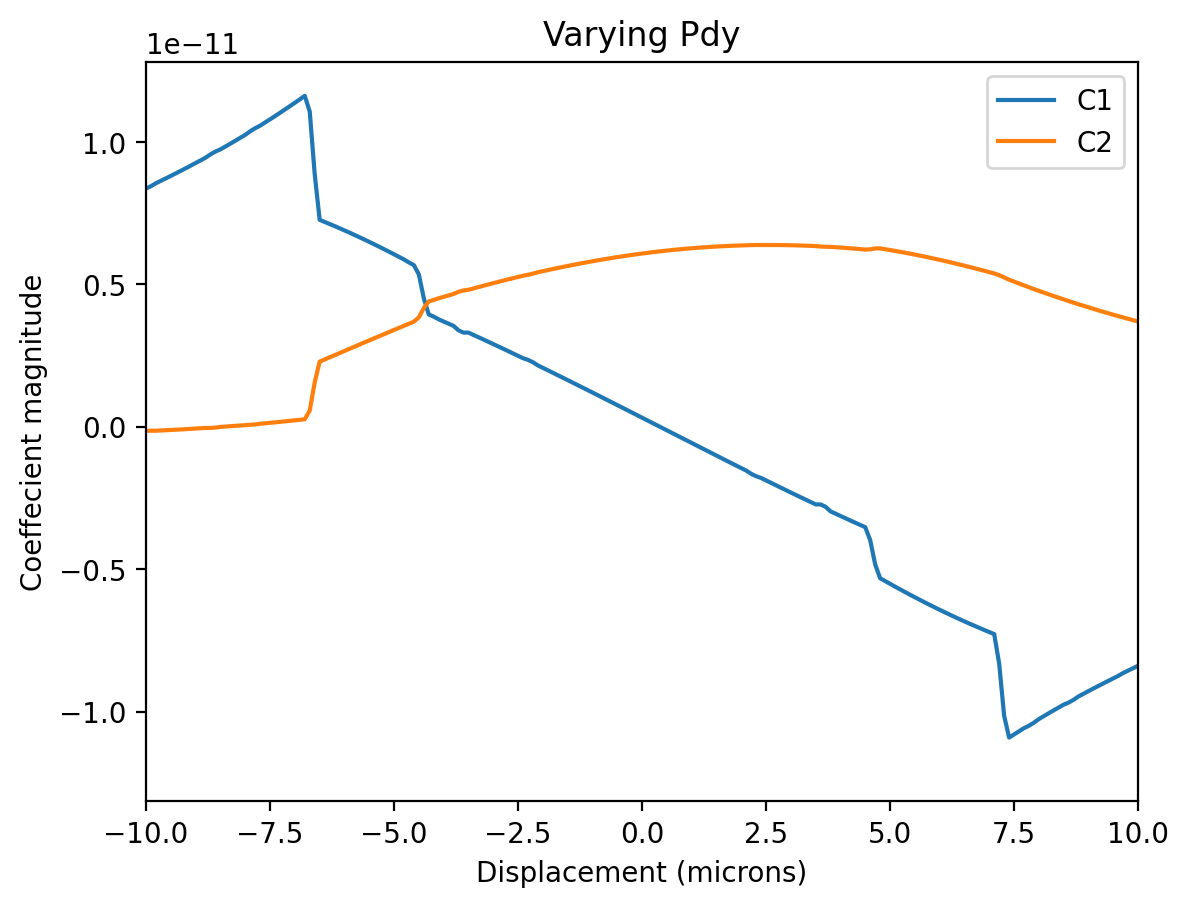

In [63]:
plt.plot(lpx, np.gradient(ars[0], 0.1), label='C1')
plt.plot(lpx, np.gradient(ars[1], 0.1), label='C2')
#plt.plot(lpx, np.gradient(ars[2], 0.1), label='C3')
#plt.plot(lpx, np.gradient(ars[3], 0.1), label='C4')
#plt.plot(lpx, np.gradient(ars[4], 0.1), label='C5')
#plt.plot(lpx, np.gradient(ars[5], 0.1), label='C6')
#plt.plot(lpx, np.gradient(ars[6], 0.1), label='C7')
#plt.plot(lpx, np.gradient(ars[7], 0.1), label='C8')
#plt.plot(lpx, np.gradient(ars[8], 0.1), label='C9')
#plt.plot(lpx, np.gradient(ars[9], 0.1), label='C10')
#plt.plot(lpx, np.gradient(ars[10], 0.1), label='C11')
plt.title("Varying Pdy")
plt.legend()
plt.xlim(-10,10)
plt.xlabel("Displacement (microns)")
plt.ylabel("Coeffecient magnitude")

Text(0, 0.5, 'Coeffecient magnitude')

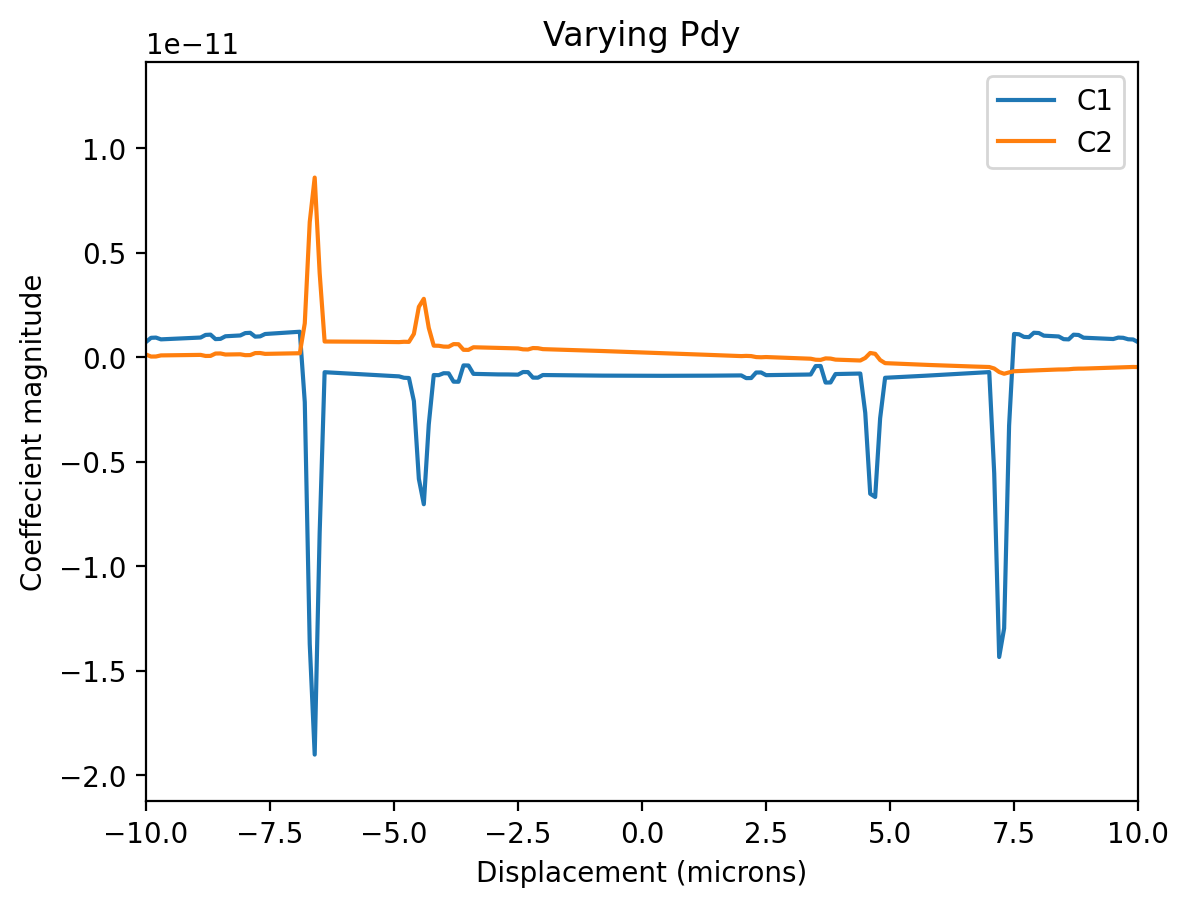

In [61]:
plt.plot(lpx, np.gradient(np.gradient(ars[0], 0.1), 0.1), label='C1')
plt.plot(lpx, np.gradient(np.gradient(ars[1], 0.1), 0.1), label='C2')
plt.xlim(-10, 10)
plt.title("Varying Pdy")
plt.legend()
plt.xlabel("Displacement (microns)")
plt.ylabel("Coeffecient magnitude")

Text(0, 0.5, 'Coeffecient magnitude')

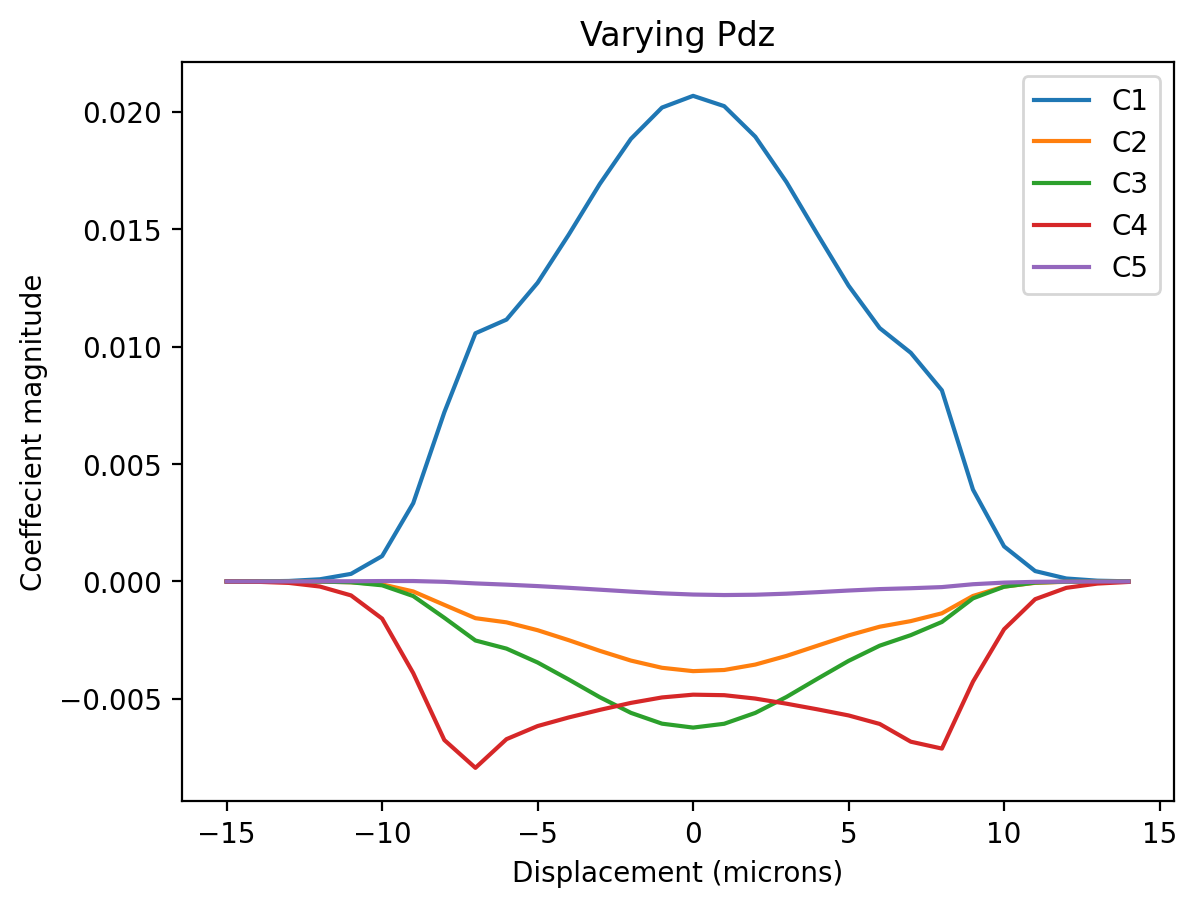

In [ ]:
plt.plot(lpx, ars[0], label='C1')
plt.plot(lpx, ars[1], label='C2')
plt.plot(lpx, ars[2], label='C3')
plt.plot(lpx, ars[3], label='C4')
plt.plot(lpx, ars[4], label='C5')
plt.title("Varying Pdz")
plt.legend()
plt.xlabel("Displacement (microns)")
plt.ylabel("Coeffecient magnitude")

Text(0, 0.5, 'Coeffecient magnitude')

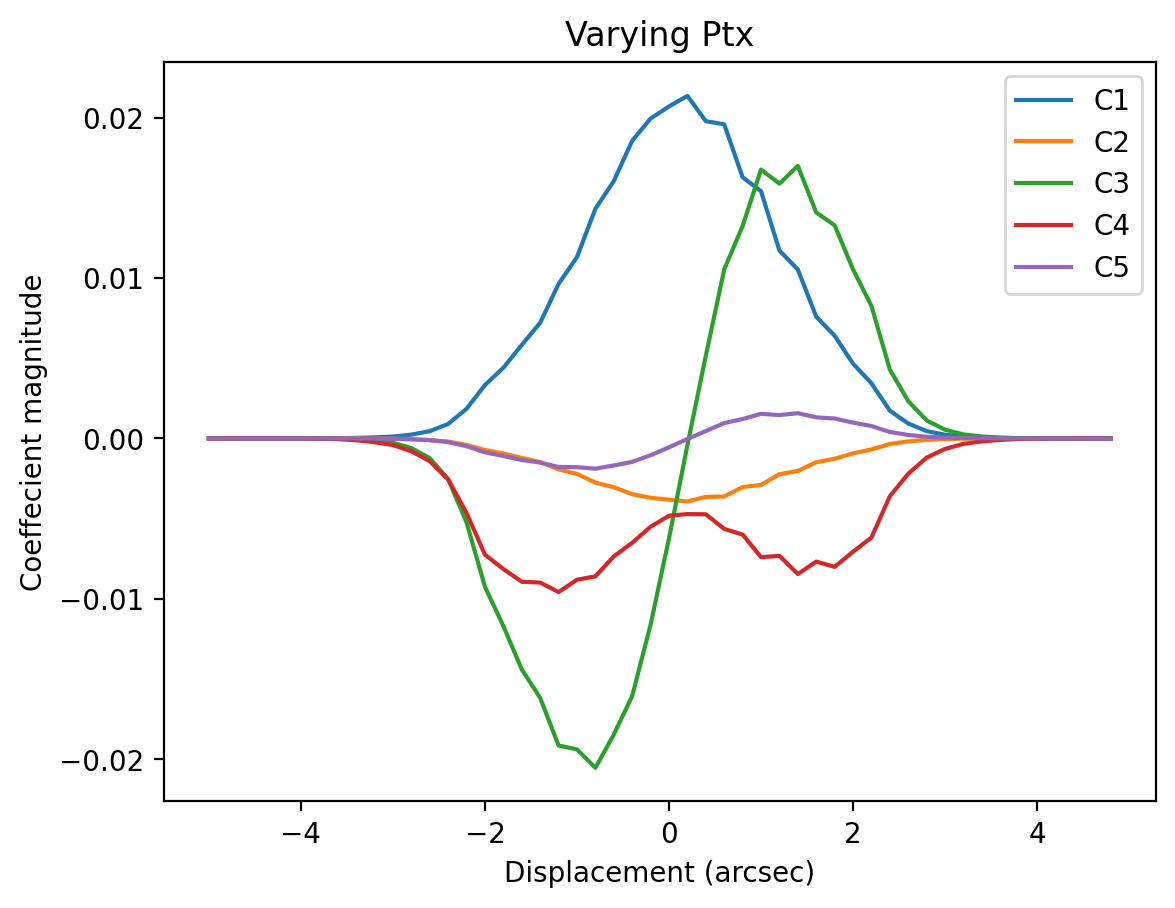

In [ ]:
plt.plot(ltx, ars[0], label='C1')
plt.plot(ltx, ars[1], label='C2')
plt.plot(ltx, ars[2], label='C3')
plt.plot(ltx, ars[3], label='C4')
plt.plot(ltx, ars[4], label='C5')
plt.title("Varying Ptx")
plt.legend()
plt.xlabel("Displacement (arcsec)")
plt.ylabel("Coeffecient magnitude")

Text(0, 0.5, 'Coeffecient magnitude')

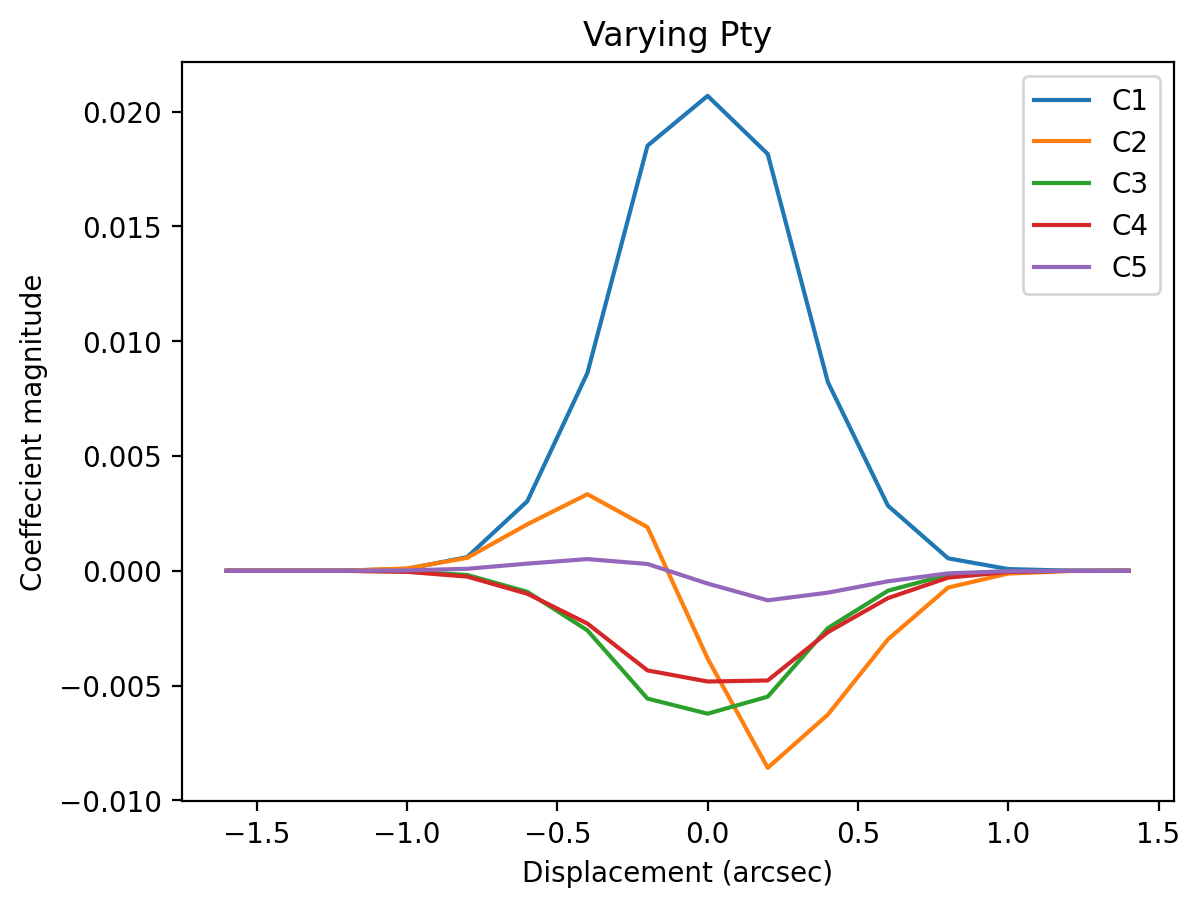

In [ ]:
plt.plot(ltx, ars[0], label='C1')
plt.plot(ltx, ars[1], label='C2')
plt.plot(ltx, ars[2], label='C3')
plt.plot(ltx, ars[3], label='C4')
plt.plot(ltx, ars[4], label='C5')
plt.title("Varying Pty")
plt.legend()
plt.xlabel("Displacement (arcsec)")
plt.ylabel("Coeffecient magnitude")

Text(0, 0.5, 'Coeffecient magnitude')

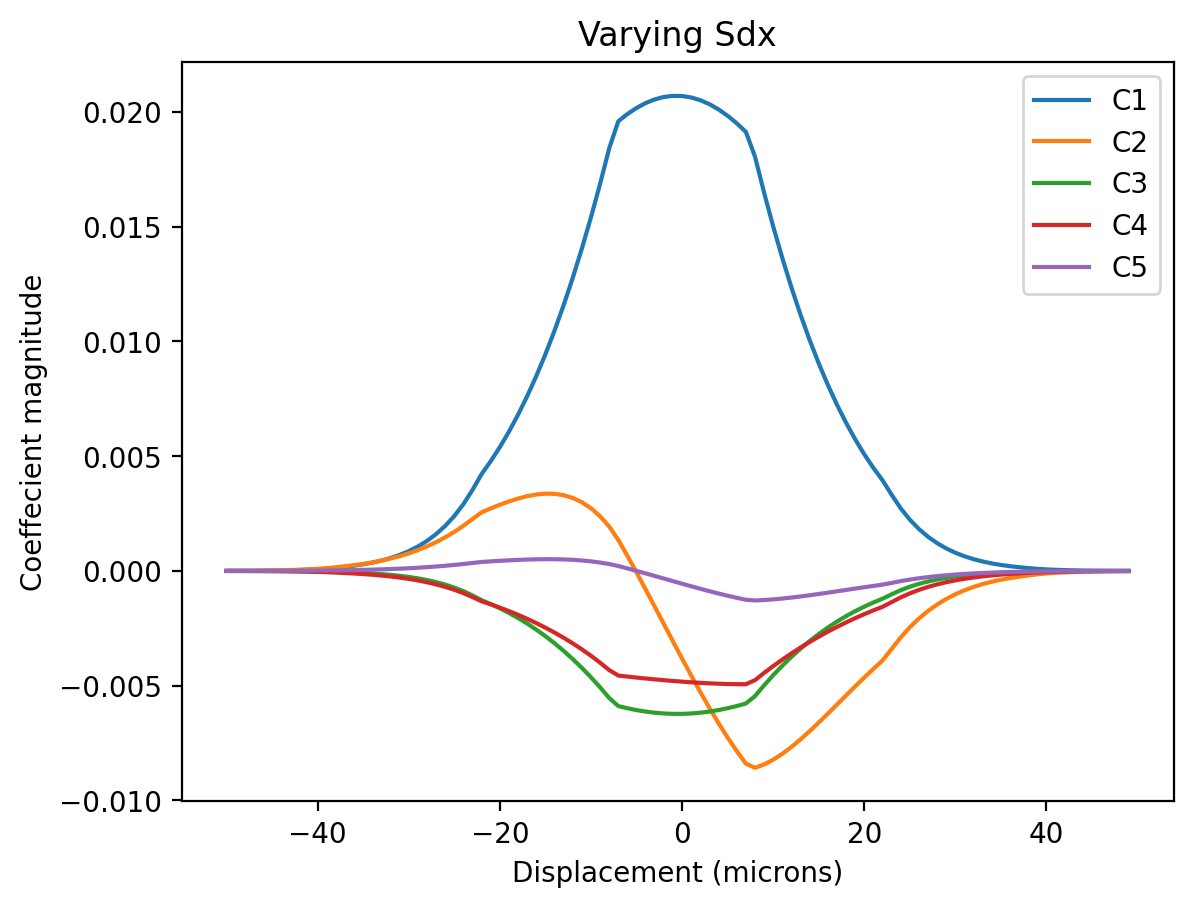

In [ ]:
plt.plot(lpx, ars[0], label='C1')
plt.plot(lpx, ars[1], label='C2')
plt.plot(lpx, ars[2], label='C3')
plt.plot(lpx, ars[3], label='C4')
plt.plot(lpx, ars[4], label='C5')
plt.title("Varying Sdx")
plt.legend()
plt.xlabel("Displacement (microns)")
plt.ylabel("Coeffecient magnitude")

Text(0, 0.5, 'Coeffecient magnitude')

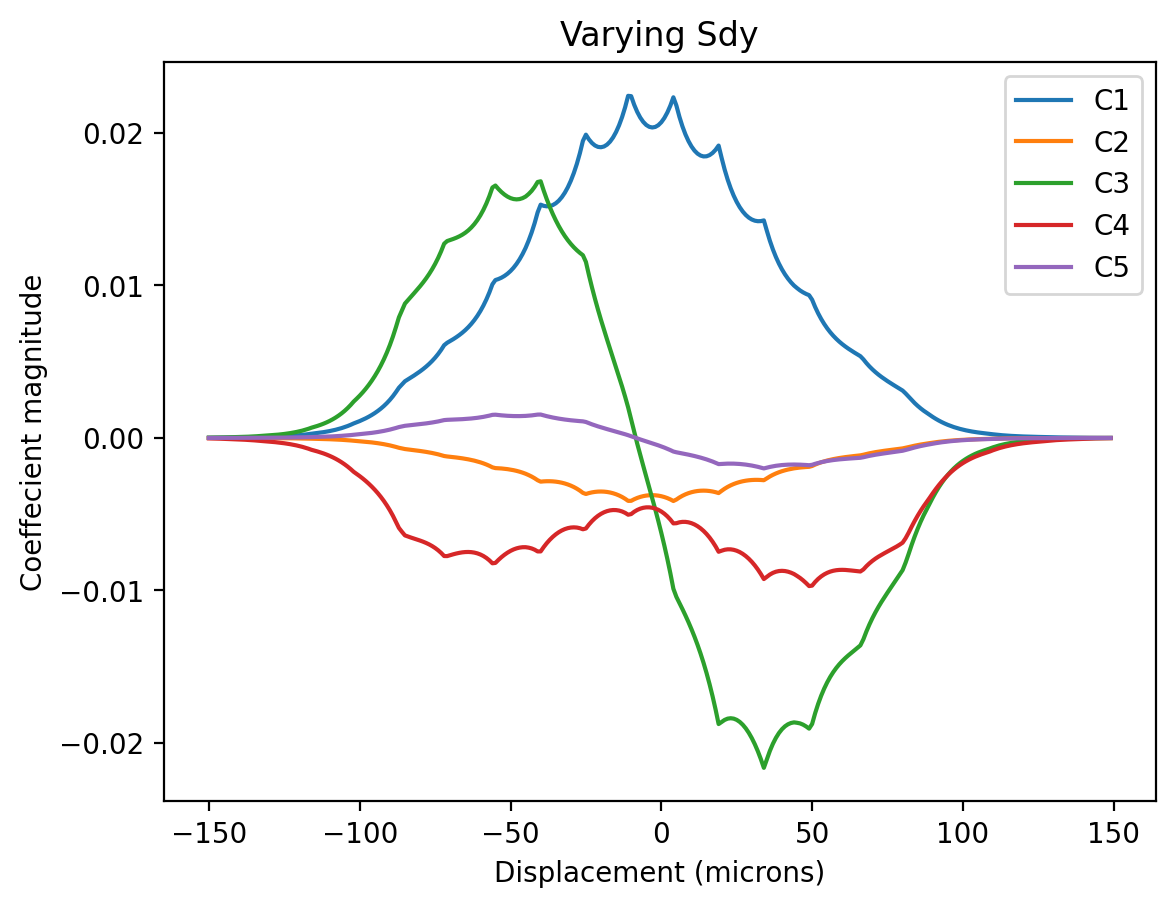

In [ ]:
plt.plot(lpx, ars[0], label='C1')
plt.plot(lpx, ars[1], label='C2')
plt.plot(lpx, ars[2], label='C3')
plt.plot(lpx, ars[3], label='C4')
plt.plot(lpx, ars[4], label='C5')
plt.title("Varying Sdy")
plt.legend()
plt.xlabel("Displacement (microns)")
plt.ylabel("Coeffecient magnitude")

Text(0, 0.5, 'Coeffecient magnitude')

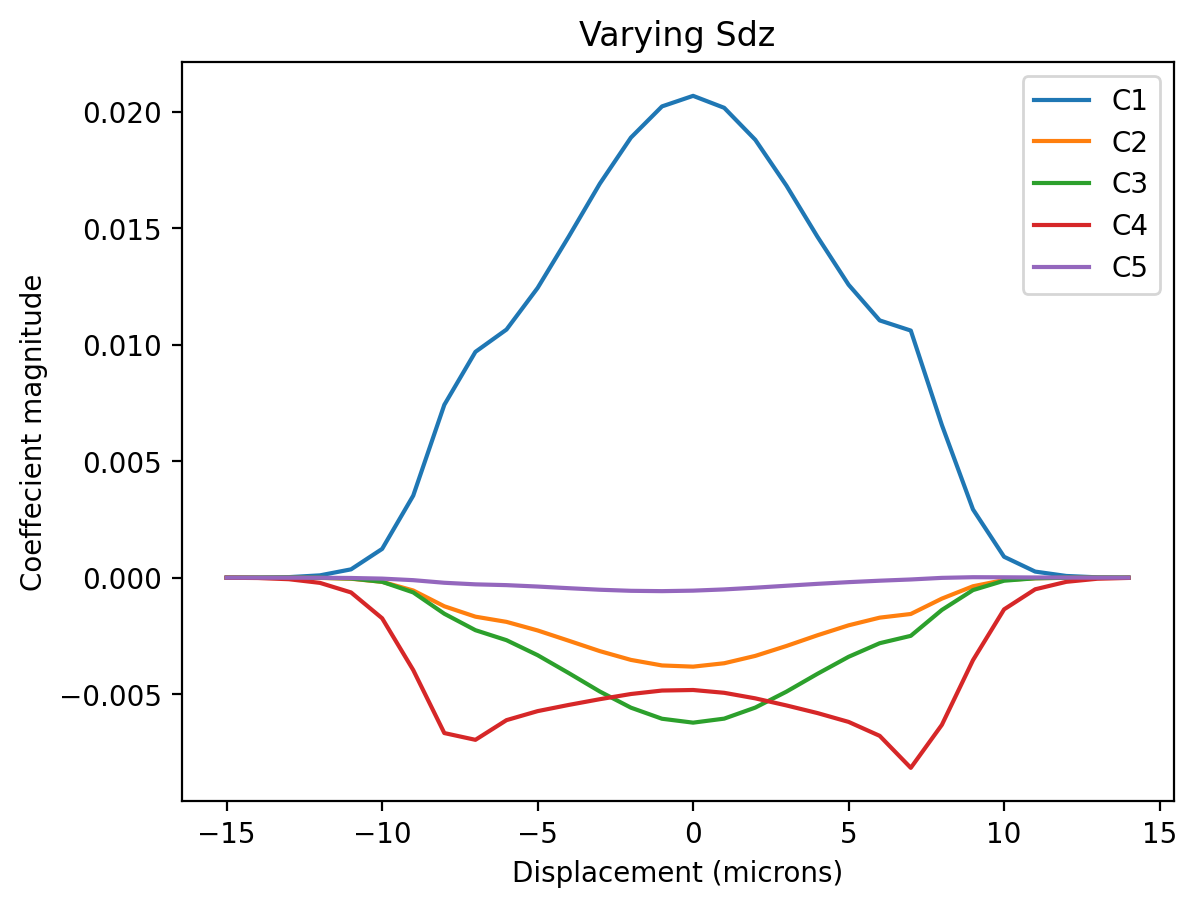

In [ ]:
plt.plot(lpx, ars[0], label='C1')
plt.plot(lpx, ars[1], label='C2')
plt.plot(lpx, ars[2], label='C3')
plt.plot(lpx, ars[3], label='C4')
plt.plot(lpx, ars[4], label='C5')
plt.title("Varying Sdz")
plt.legend()
plt.xlabel("Displacement (microns)")
plt.ylabel("Coeffecient magnitude")

Text(0, 0.5, 'Coeffecient magnitude')

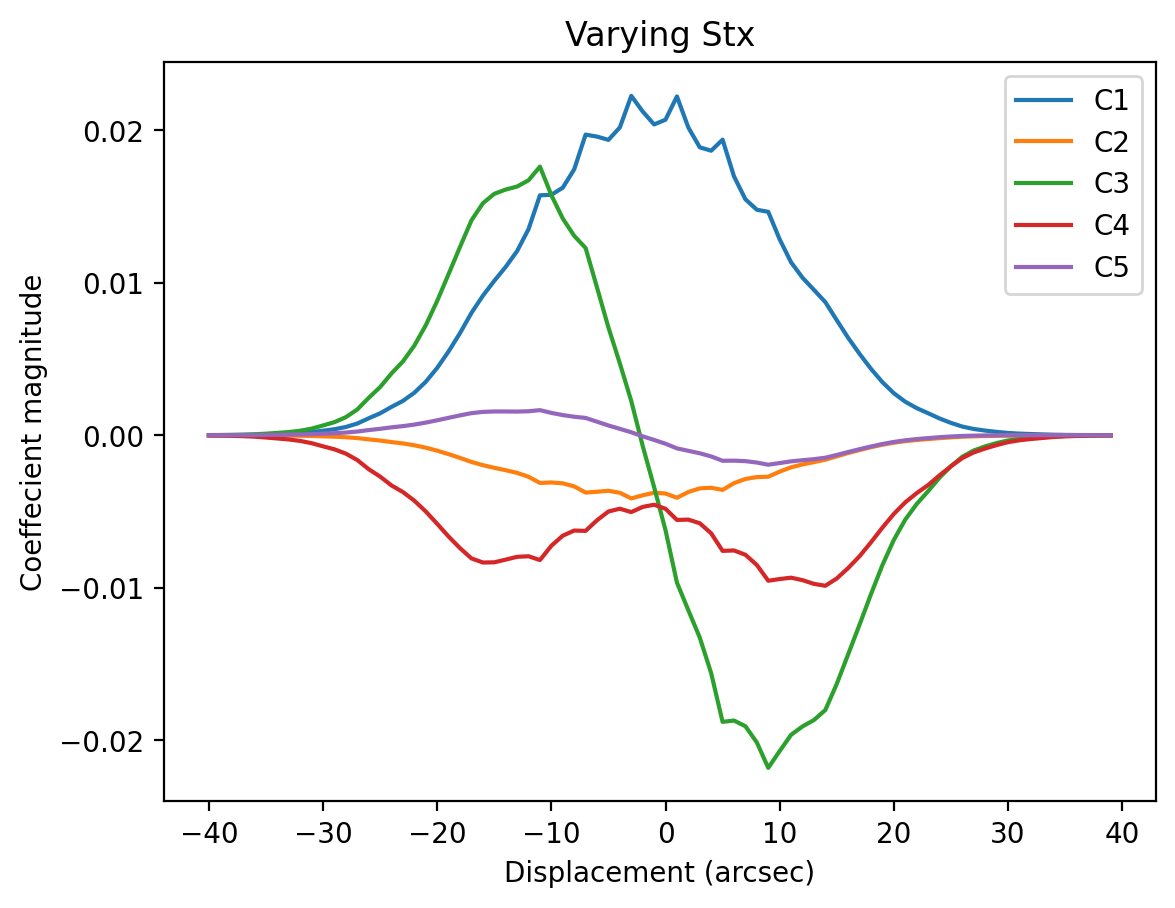

In [ ]:
plt.plot(ltx, ars[0], label='C1')
plt.plot(ltx, ars[1], label='C2')
plt.plot(ltx, ars[2], label='C3')
plt.plot(ltx, ars[3], label='C4')
plt.plot(ltx, ars[4], label='C5')
plt.title("Varying Stx")
plt.legend()
plt.xlabel("Displacement (arcsec)")
plt.ylabel("Coeffecient magnitude")

Text(0, 0.5, 'Coeffecient magnitude')

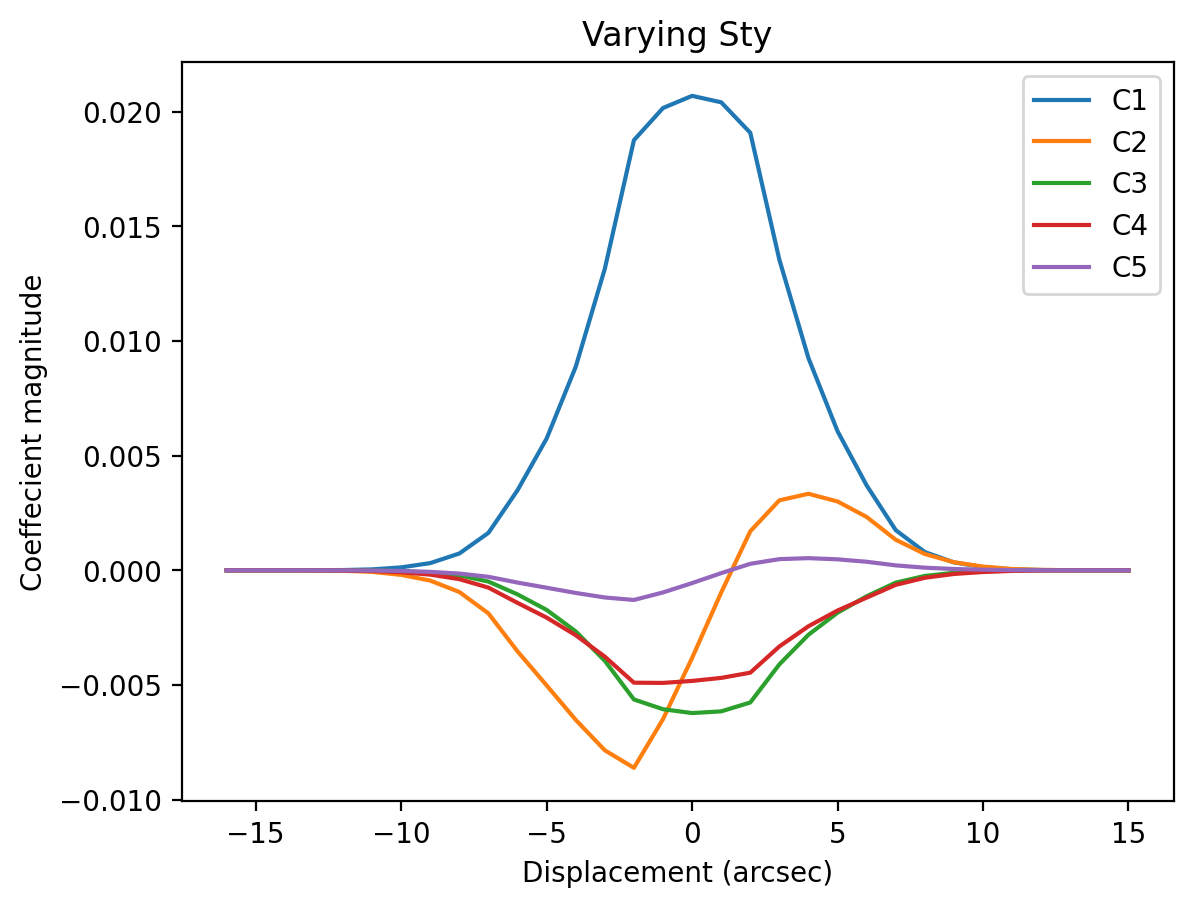

In [ ]:
plt.plot(ltx, ars[0], label='C1')
plt.plot(ltx, ars[1], label='C2')
plt.plot(ltx, ars[2], label='C3')
plt.plot(ltx, ars[3], label='C4')
plt.plot(ltx, ars[4], label='C5')
plt.title("Varying Sty")
plt.legend()
plt.xlabel("Displacement (arcsec)")
plt.ylabel("Coeffecient magnitude")

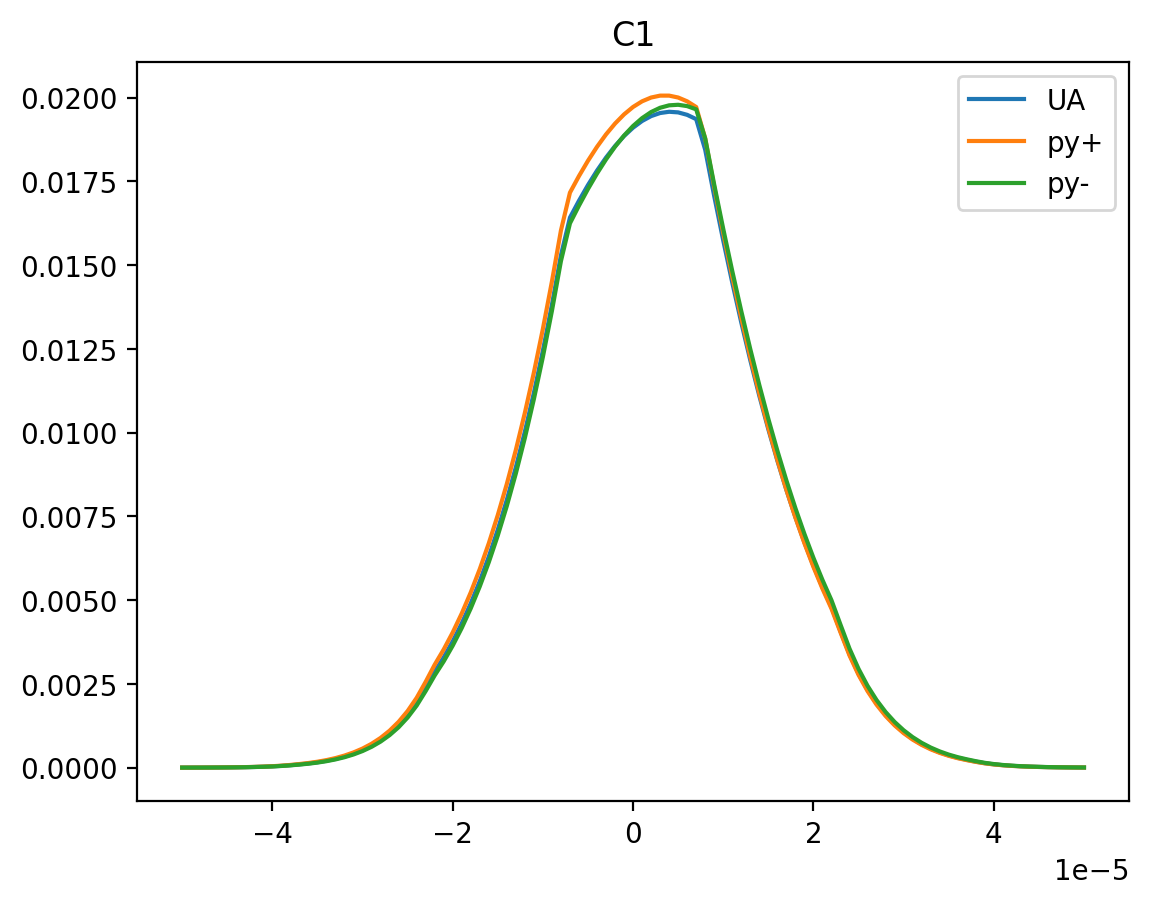

In [ ]:
plt.plot(lpx, vec_genpsf(px=lpx), label='UA')
plt.plot(lpx, vec_genpsf(px=lpx, py=0.000003), label='py+')
plt.plot(lpx, vec_genpsf(px=lpx, py=-0.000003), label='py-')
plt.title("C1")
plt.legend()

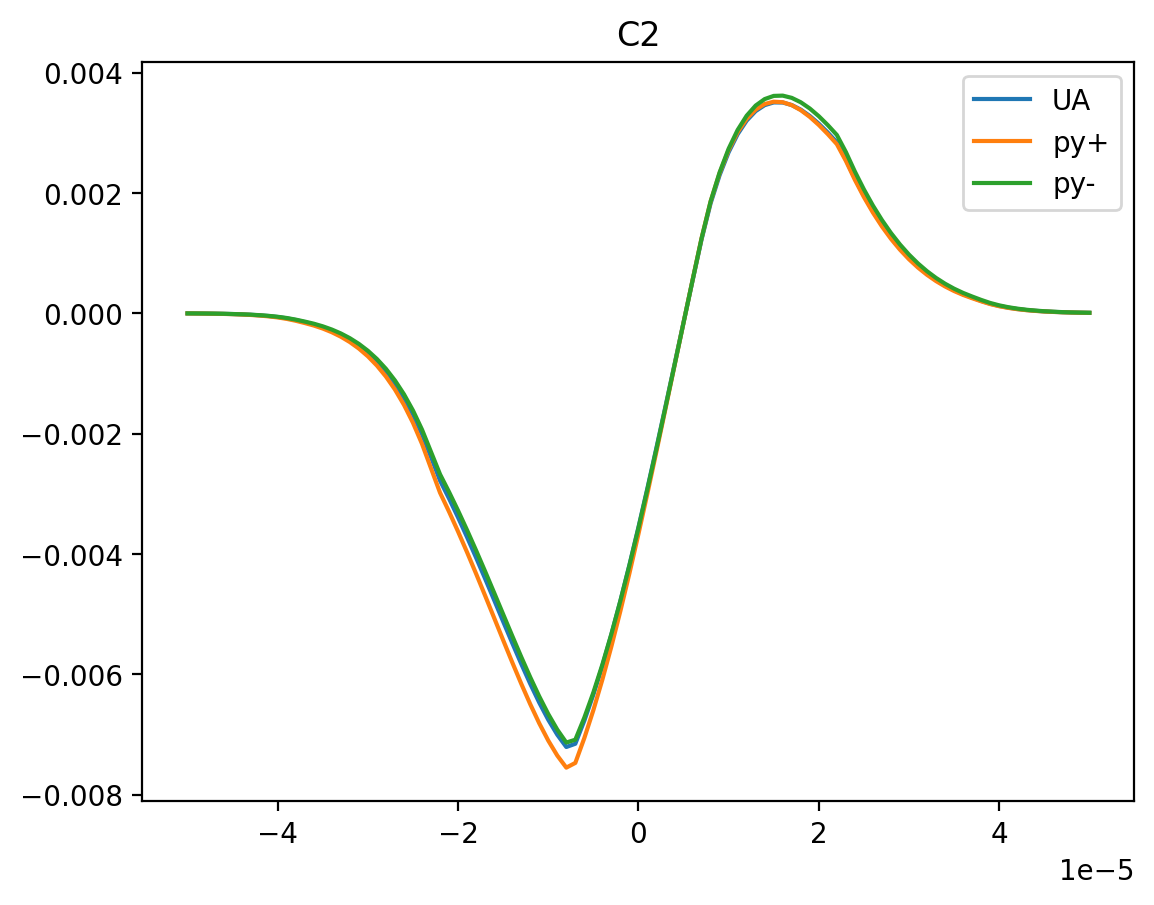

In [ ]:
plt.plot(lpx, vec_genpsf(px=lpx), label='UA')
plt.plot(lpx, vec_genpsf(px=lpx, py=0.000003), label='py+')
plt.plot(lpx, vec_genpsf(px=lpx, py=-0.000003), label='py-')
plt.title("C2")
plt.legend()

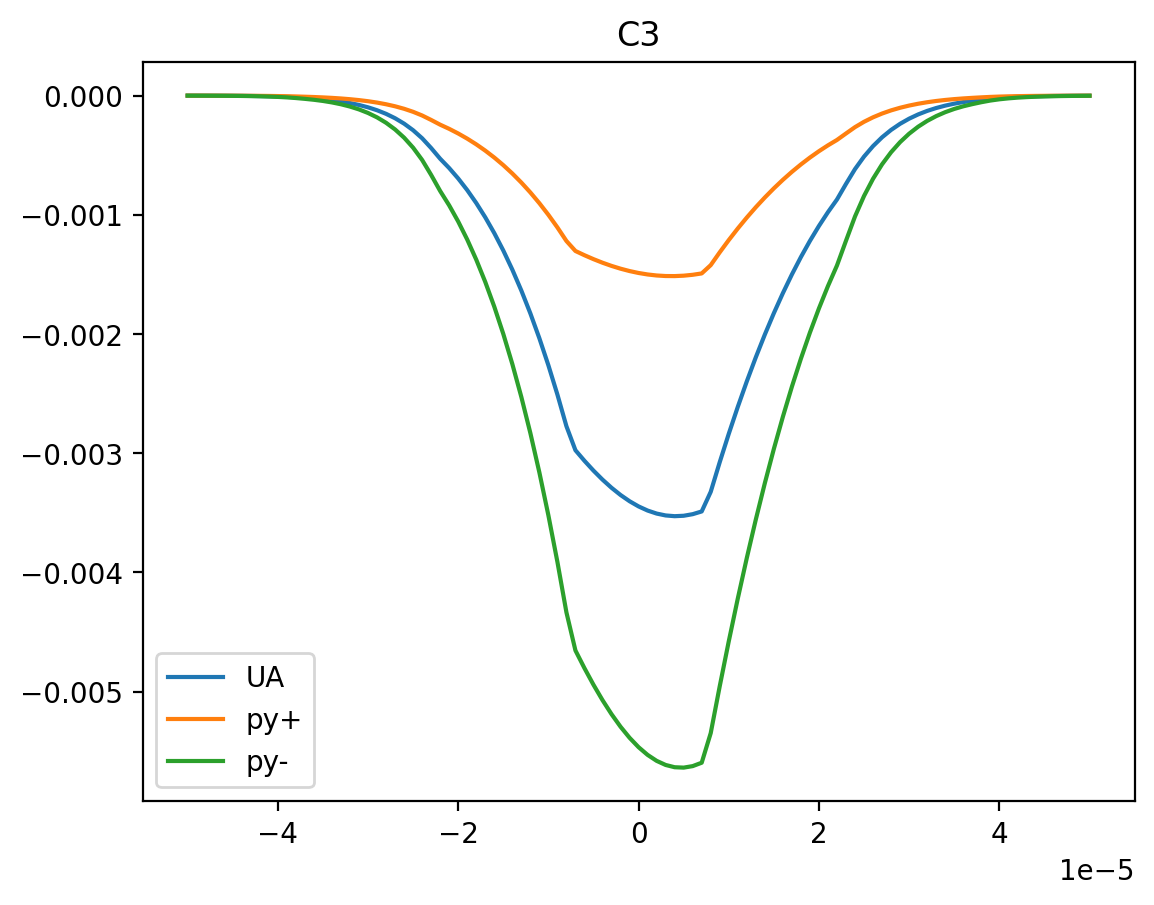

In [ ]:
plt.plot(lpx, vec_genpsf(px=lpx), label='UA')
plt.plot(lpx, vec_genpsf(px=lpx, py=0.000003), label='py+')
plt.plot(lpx, vec_genpsf(px=lpx, py=-0.000003), label='py-')
plt.title("C3")
plt.legend()

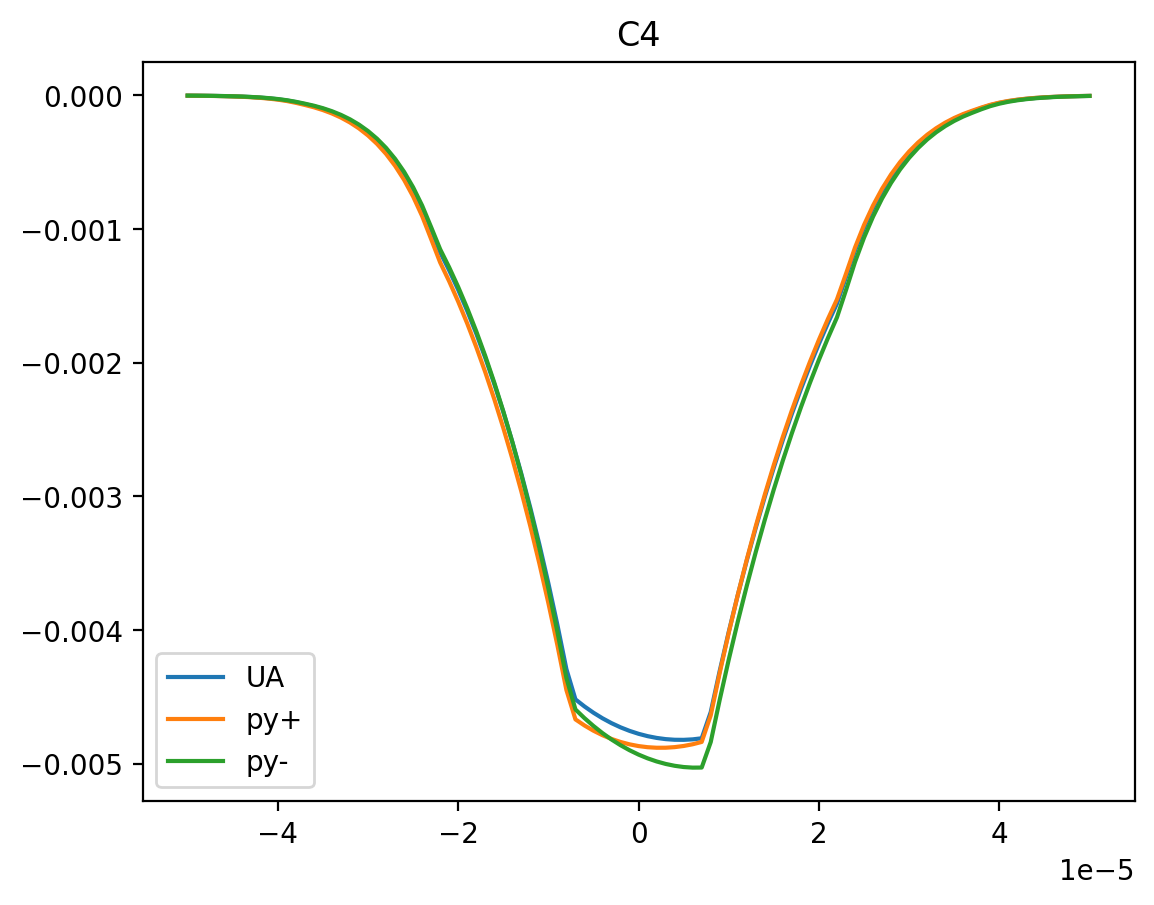

In [ ]:
plt.plot(lpx, vec_genpsf(px=lpx), label='UA')
plt.plot(lpx, vec_genpsf(px=lpx, py=0.000003), label='py+')
plt.plot(lpx, vec_genpsf(px=lpx, py=-0.000003), label='py-')
plt.title("C4")
plt.legend()

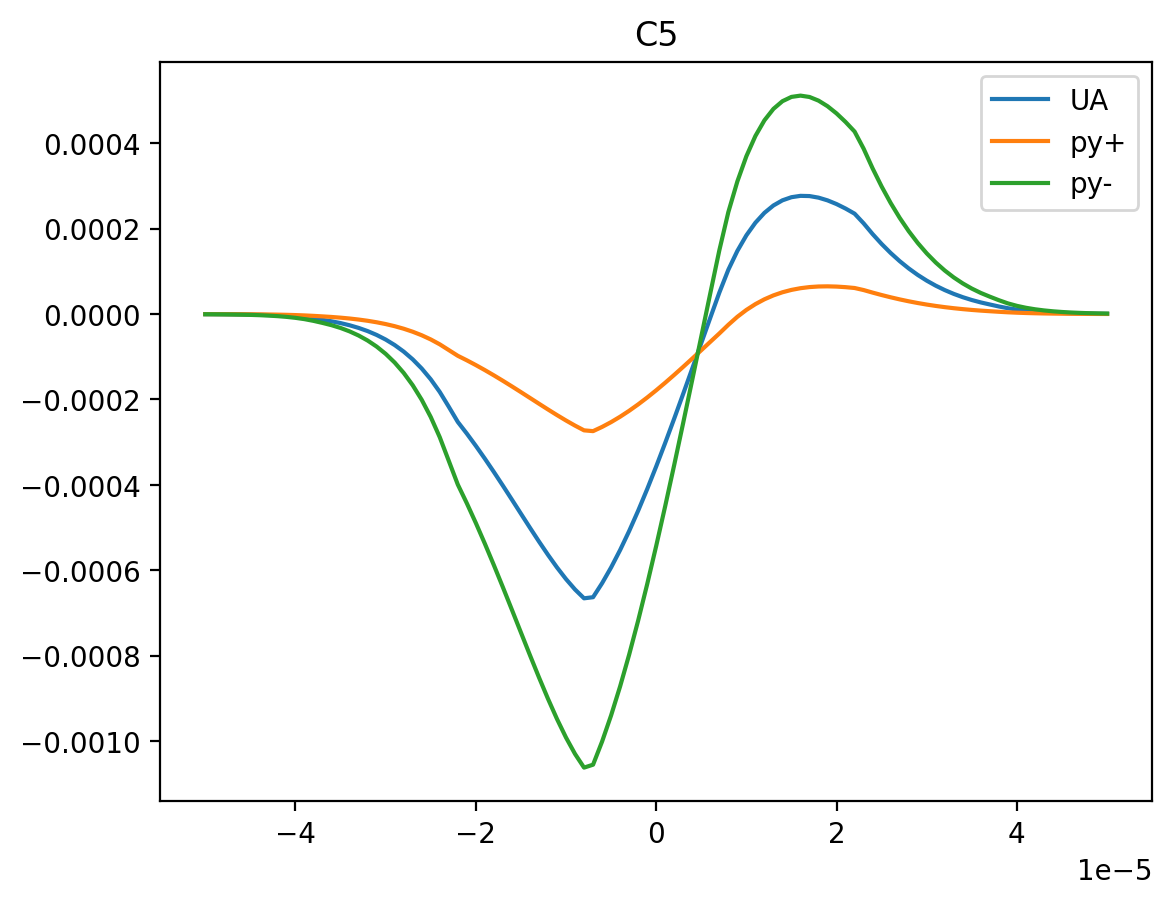

In [ ]:
plt.plot(lpx, vec_genpsf(px=lpx), label='UA')
plt.plot(lpx, vec_genpsf(px=lpx, py=0.000003), label='py+')
plt.plot(lpx, vec_genpsf(px=lpx, py=-0.000003), label='py-')
plt.title("C5")
plt.legend()

In [ ]:
from scipy.stats import sobol_indices, uniform

In [ ]:
def f_tel(x):

    ars = vec_genpsf(650e-9, x[0], x[1], 0, 0, 0, 0, 0, 0, 0, 0, 1)
    ars = np.array(ars.tolist()).T[0]

    return ars

indices = sobol_indices(func=f_tel, n=1024, dists=[uniform(loc=-20, scale=40),uniform(loc=-20, scale=40)])

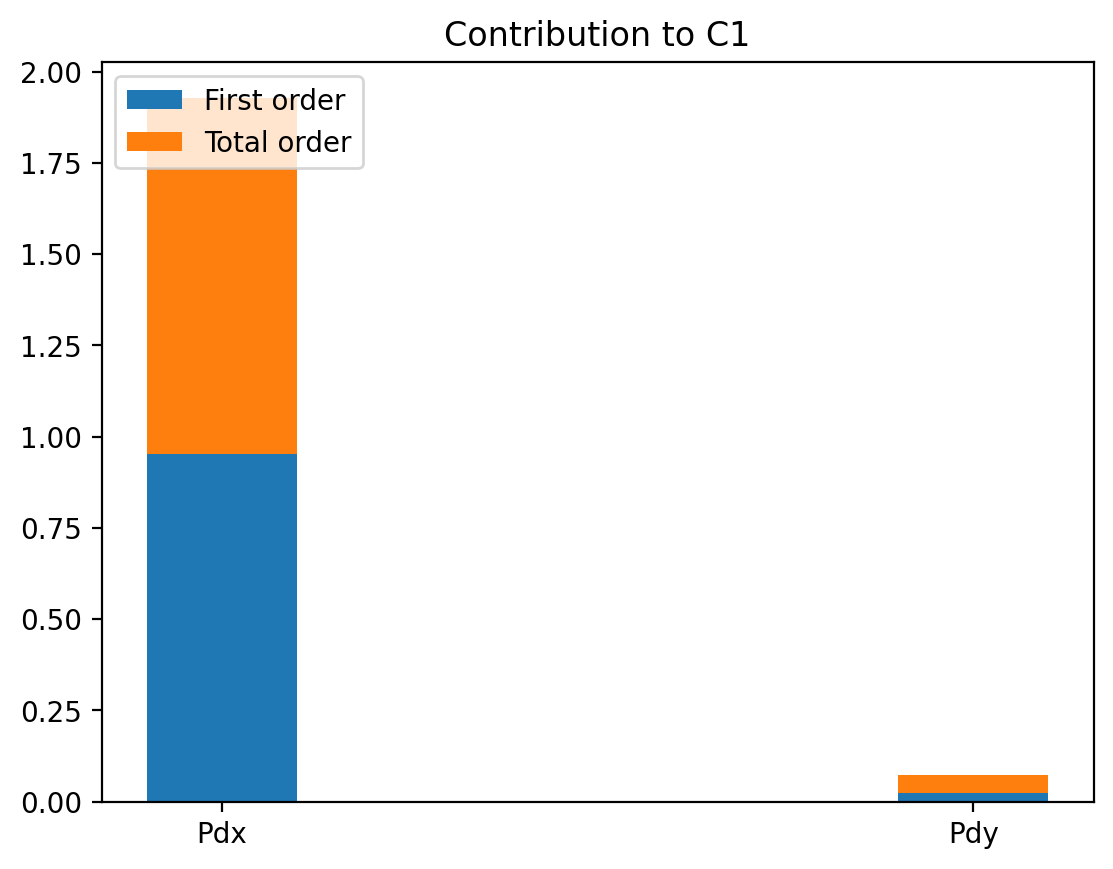

In [ ]:
de = (
    "Pdx",
    "Pdy"
)
weight_counts = {
    "First order": indices.first_order,
    "Total order": indices.total_order,
}
width = 0.2

fig, ax = plt.subplots()
bottom = np.zeros(2)

for boolean, weight_count in weight_counts.items():
    p = ax.bar(de, weight_count, width, label=boolean, bottom=bottom)
    bottom += weight_count

ax.set_title("Contribution to C1")
ax.legend(loc="upper left")

plt.show()

In [ ]:
def f_tel(x):

    ars = vec_genpsf(650e-9, x[0], x[1], 0, 0, 0, 0, 0, 0, 0, 0, 2)
    ars = np.array(ars.tolist()).T[1]

    return ars

indices = sobol_indices(func=f_tel, n=1024, dists=[uniform(loc=-20, scale=40),uniform(loc=-20, scale=40)])

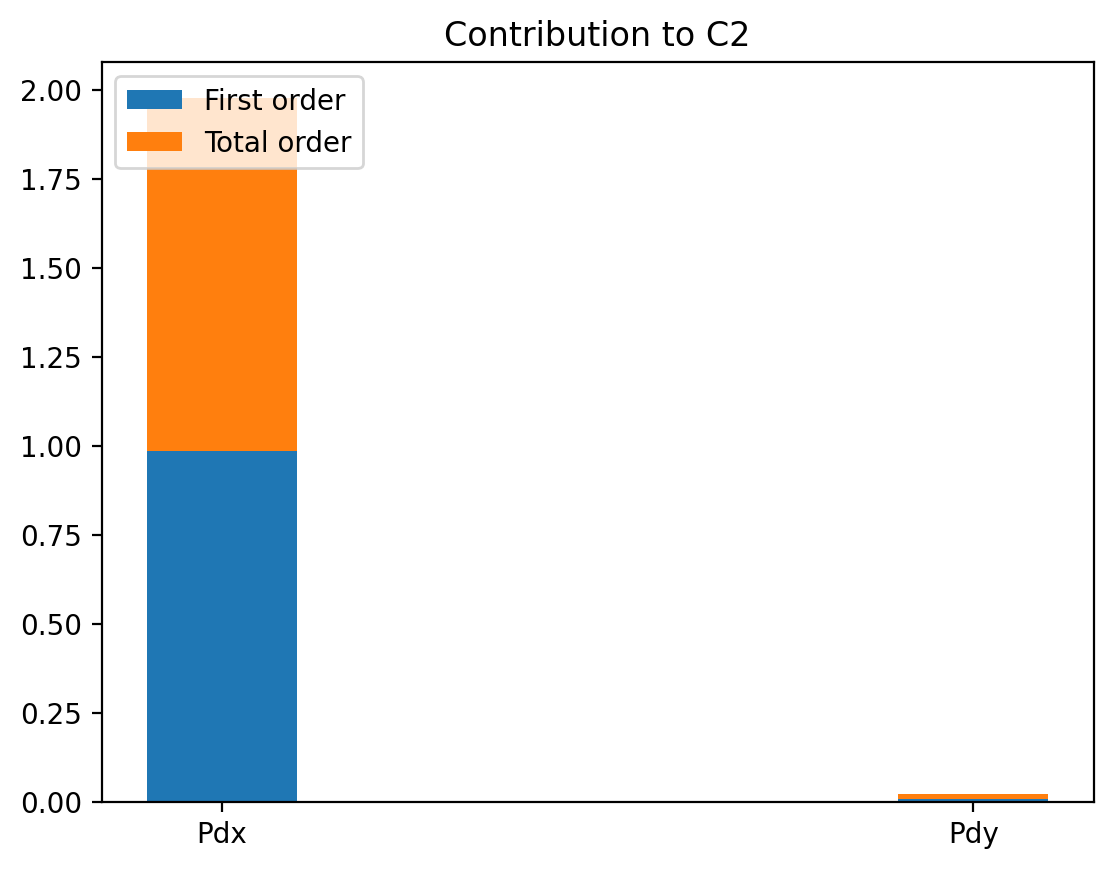

In [ ]:
de = (
    "Pdx",
    "Pdy"
)
weight_counts = {
    "First order": indices.first_order,
    "Total order": indices.total_order,
}
width = 0.2

fig, ax = plt.subplots()
bottom = np.zeros(2)

for boolean, weight_count in weight_counts.items():
    p = ax.bar(de, weight_count, width, label=boolean, bottom=bottom)
    bottom += weight_count

ax.set_title("Contribution to C2")
ax.legend(loc="upper left")

plt.show()

In [ ]:
def f_tel(x):

    ars = vec_genpsf(650e-9, x[0], x[1], 0, 0, 0, 0, 0, 0, 0, 0, 3)
    ars = np.array(ars.tolist()).T[2]

    return ars

indices = sobol_indices(func=f_tel, n=1024, dists=[uniform(loc=-20, scale=40),uniform(loc=-20, scale=40)])

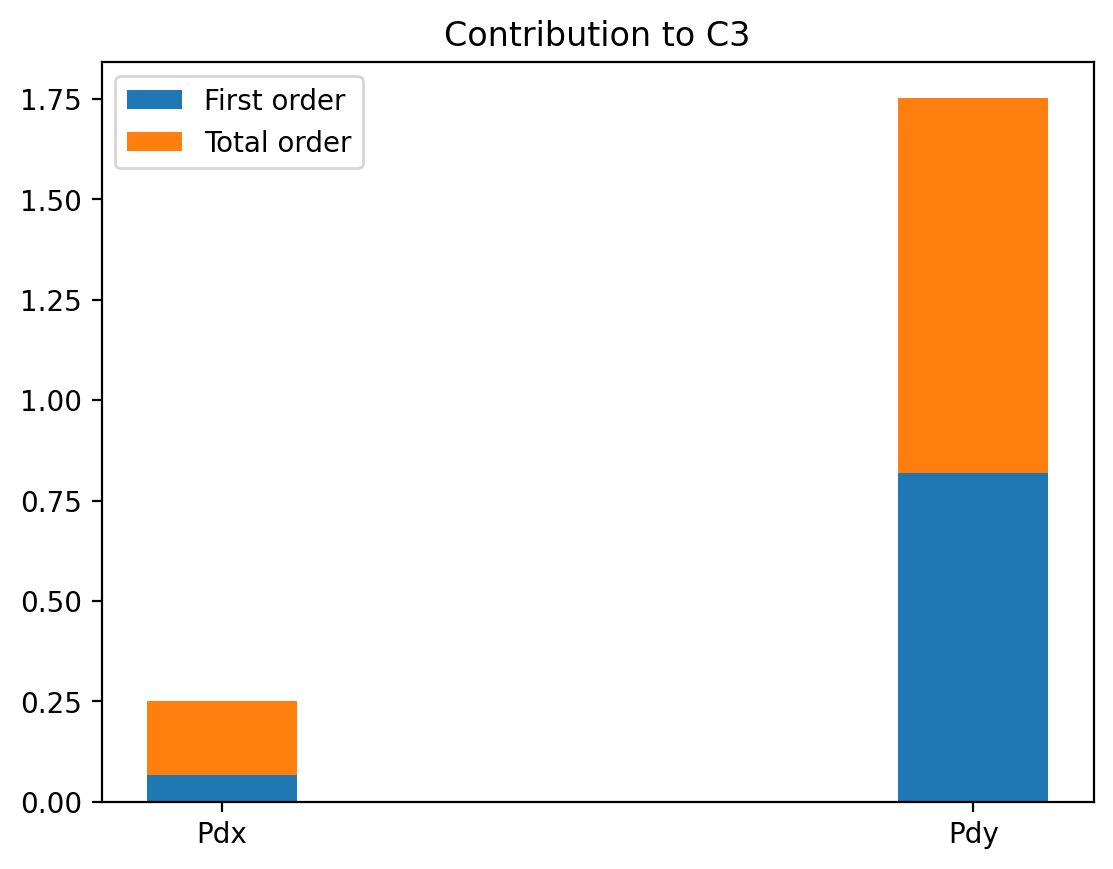

In [ ]:
de = (
    "Pdx",
    "Pdy"
)
weight_counts = {
    "First order": indices.first_order,
    "Total order": indices.total_order,
}
width = 0.2

fig, ax = plt.subplots()
bottom = np.zeros(2)

for boolean, weight_count in weight_counts.items():
    p = ax.bar(de, weight_count, width, label=boolean, bottom=bottom)
    bottom += weight_count

ax.set_title("Contribution to C3")
ax.legend(loc="upper left")

plt.show()

In [ ]:
def f_tel(x):

    ars = vec_genpsf(650e-9, x[0], x[1], 0, 0, 0, 0, 0, 0, 0, 0, 4)
    ars = np.array(ars.tolist()).T[3]

    return ars

indices = sobol_indices(func=f_tel, n=1024, dists=[uniform(loc=-20, scale=40),uniform(loc=-20, scale=40)])

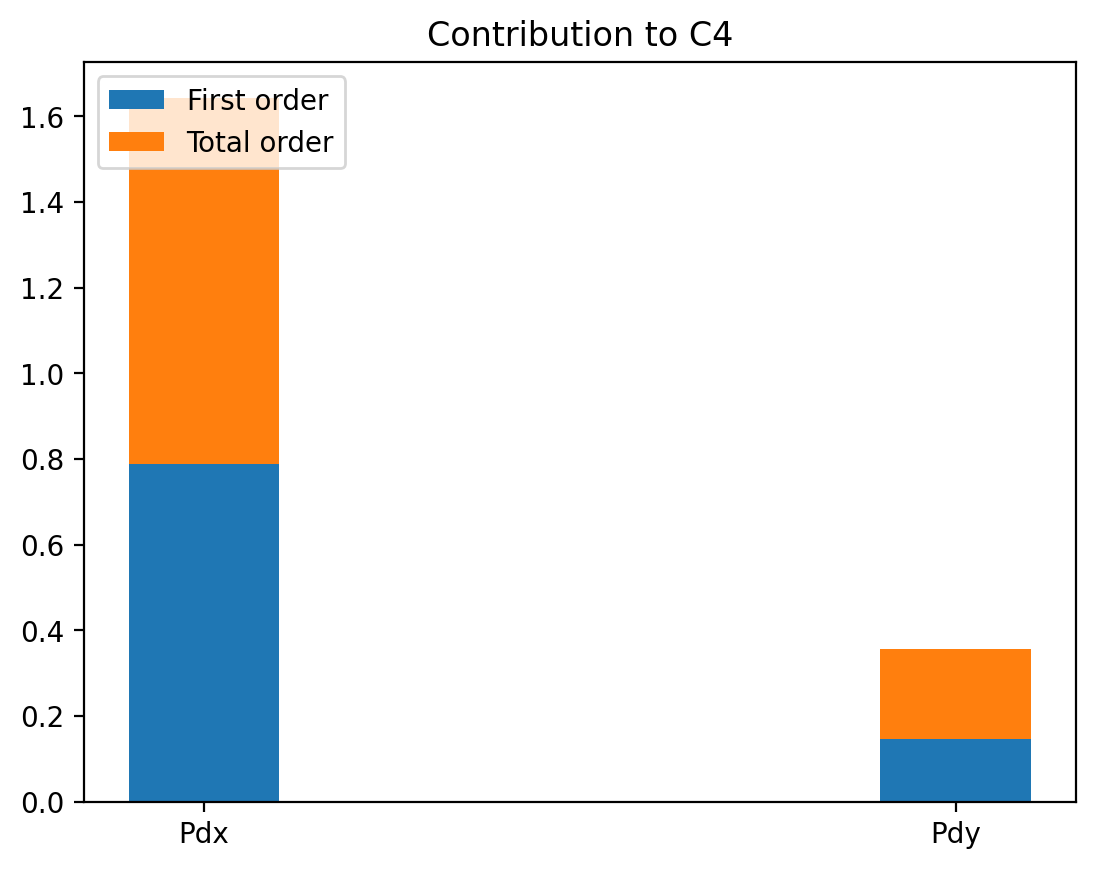

In [ ]:
de = (
    "Pdx",
    "Pdy"
)
weight_counts = {
    "First order": indices.first_order,
    "Total order": indices.total_order,
}
width = 0.2

fig, ax = plt.subplots()
bottom = np.zeros(2)

for boolean, weight_count in weight_counts.items():
    p = ax.bar(de, weight_count, width, label=boolean, bottom=bottom)
    bottom += weight_count

ax.set_title("Contribution to C4")
ax.legend(loc="upper left")

plt.show()

In [ ]:
def f_tel(x):

    ars = vec_genpsf(650e-9, x[0], x[1], 0, 0, 0, 0, 0, 0, 0, 0, 5)
    ars = np.array(ars.tolist()).T[4]

    return ars

indices = sobol_indices(func=f_tel, n=1024, dists=[uniform(loc=-20, scale=40),uniform(loc=-20, scale=40)])

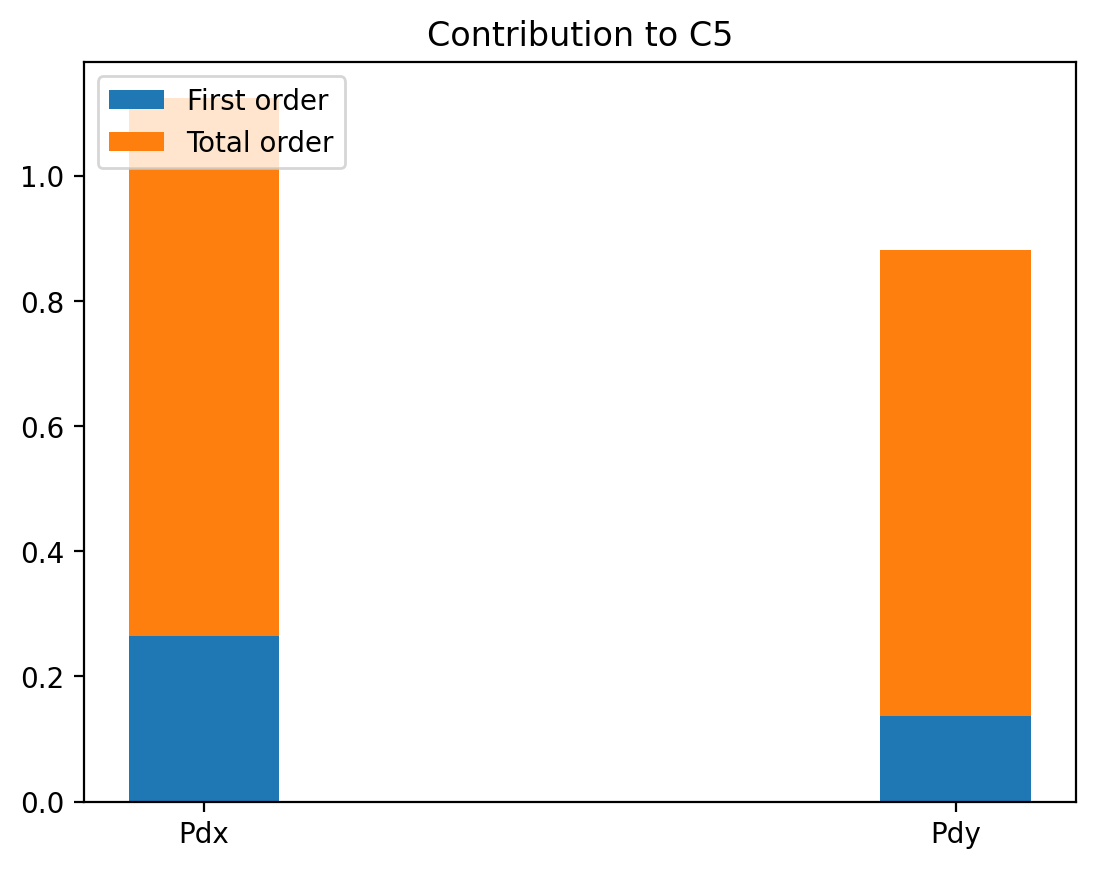

In [ ]:
de = (
    "Pdx",
    "Pdy"
)
weight_counts = {
    "First order": indices.first_order,
    "Total order": indices.total_order,
}
width = 0.2

fig, ax = plt.subplots()
bottom = np.zeros(2)

for boolean, weight_count in weight_counts.items():
    p = ax.bar(de, weight_count, width, label=boolean, bottom=bottom)
    bottom += weight_count

ax.set_title("Contribution to C5")
ax.legend(loc="upper left")

plt.show()

Text(0, 0.5, 'Pdy (microns)')

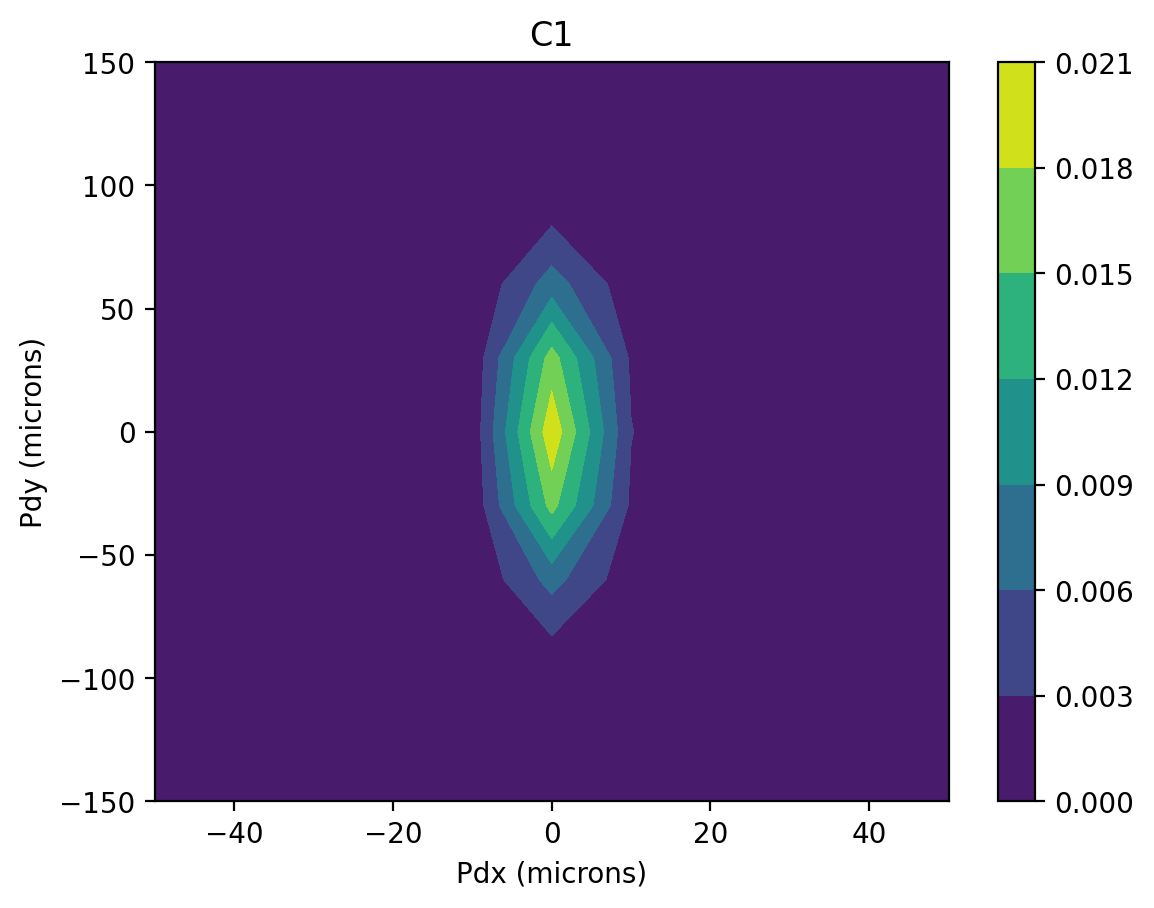

In [ ]:
x = np.arange(-50, 60, 10)
y = np.arange(-150, 180, 30)
xx, yy = np.meshgrid(x, y)
#vec_genpsf = np.frompyfunc(genpsf, 12, 1)
ars = vec_genpsf(650e-9, xx, yy, 0, 0, 0, 0, 0, 0, 0, 0, 1)
ars = np.array(ars.tolist()).T[0]
h = plt.pcolormesh(x,y,ars)
plt.colorbar()
plt.title("C1")
plt.xlabel("Pdx (microns)")
plt.ylabel("Pdy (microns)")

Text(0, 0.5, 'Pdy (microns)')

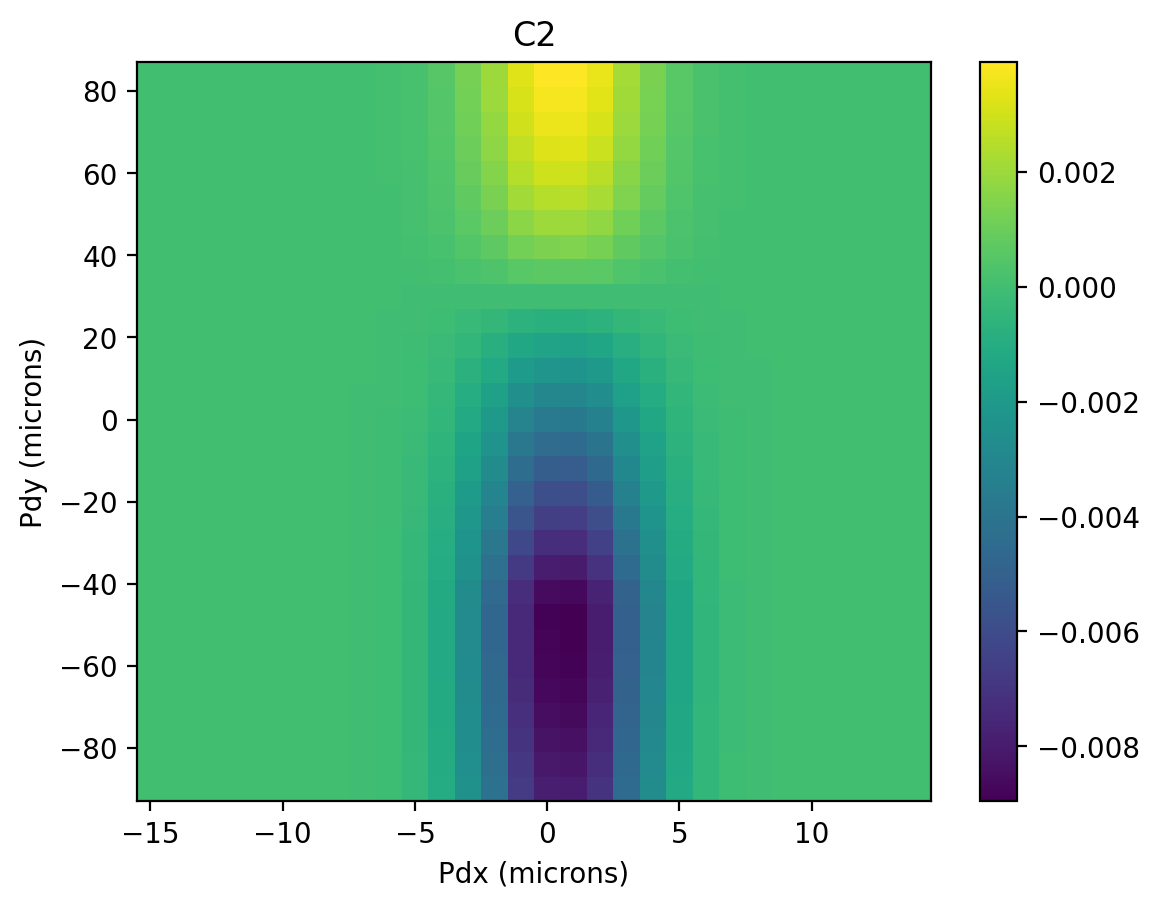

In [69]:
x = np.arange(-15, 15, 1)
y = np.arange(-90, 90, 6)
xx, yy = np.meshgrid(x, y)
#vec_genpsf = np.frompyfunc(genpsf, 12, 1)
ars = vec_genpsf(650e-9, xx, yy, 0, 0, 0, 0, 0, 0, 0, 0, 2)
ars = np.array(ars.tolist()).T[1]
h = plt.pcolormesh(x,y,ars)
plt.colorbar()
plt.title("C2")
plt.xlabel("Pdx (microns)")
plt.ylabel("Pdy (microns)")

Text(0, 0.5, 'Pdy (microns)')

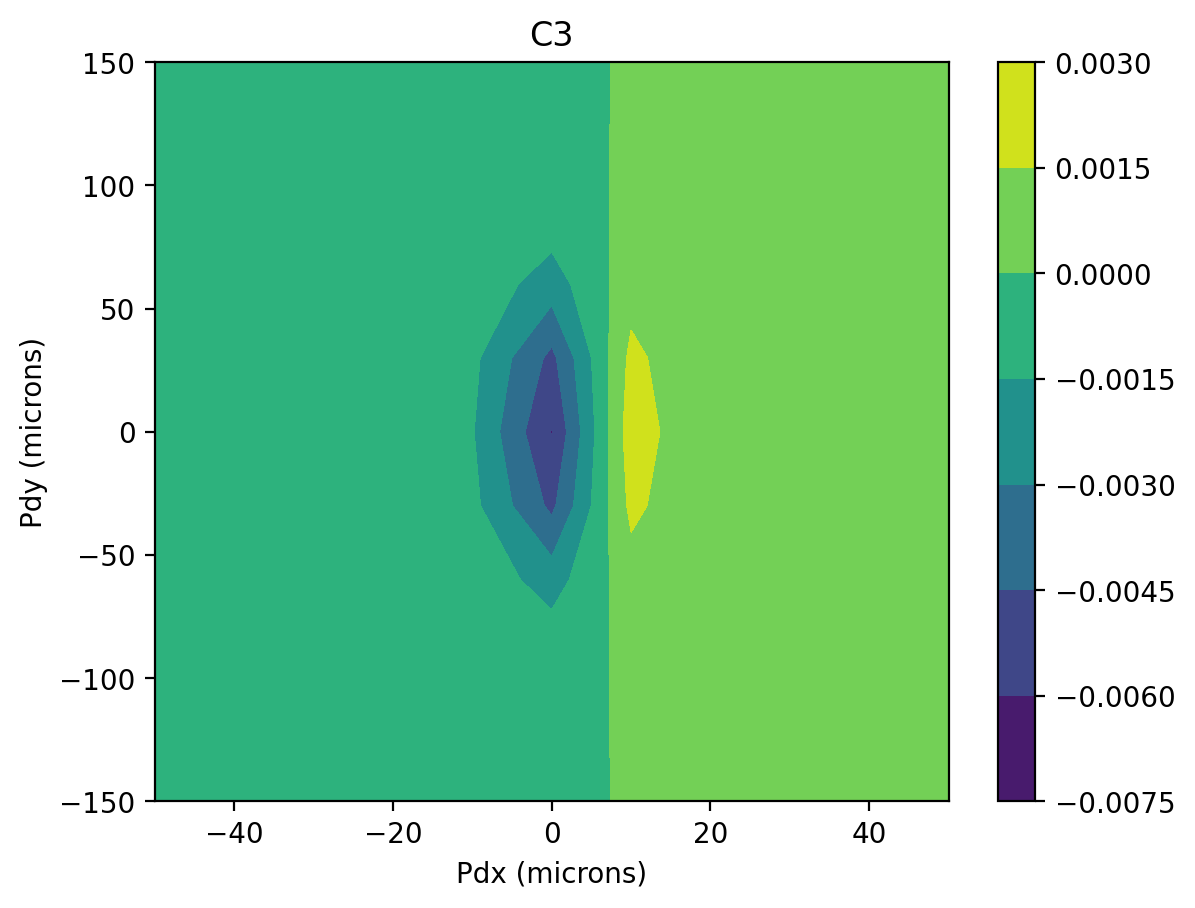

In [106]:
x = np.arange(-50, 60, 10)
y = np.arange(-150, 180, 30)
xx, yy = np.meshgrid(x, y)
#vec_genpsf = np.frompyfunc(genpsf, 12, 1)
ars = vec_genpsf(650e-9, xx, yy, 0, 0, 0, 0, 0, 0, 0, 0, 3)
ars = np.array(ars.tolist()).T[2]
h = plt.contourf(x,y,ars)
plt.colorbar()
plt.title("C3")
plt.xlabel("Pdx (microns)")
plt.ylabel("Pdy (microns)")

Text(0, 0.5, 'Pdy (microns)')

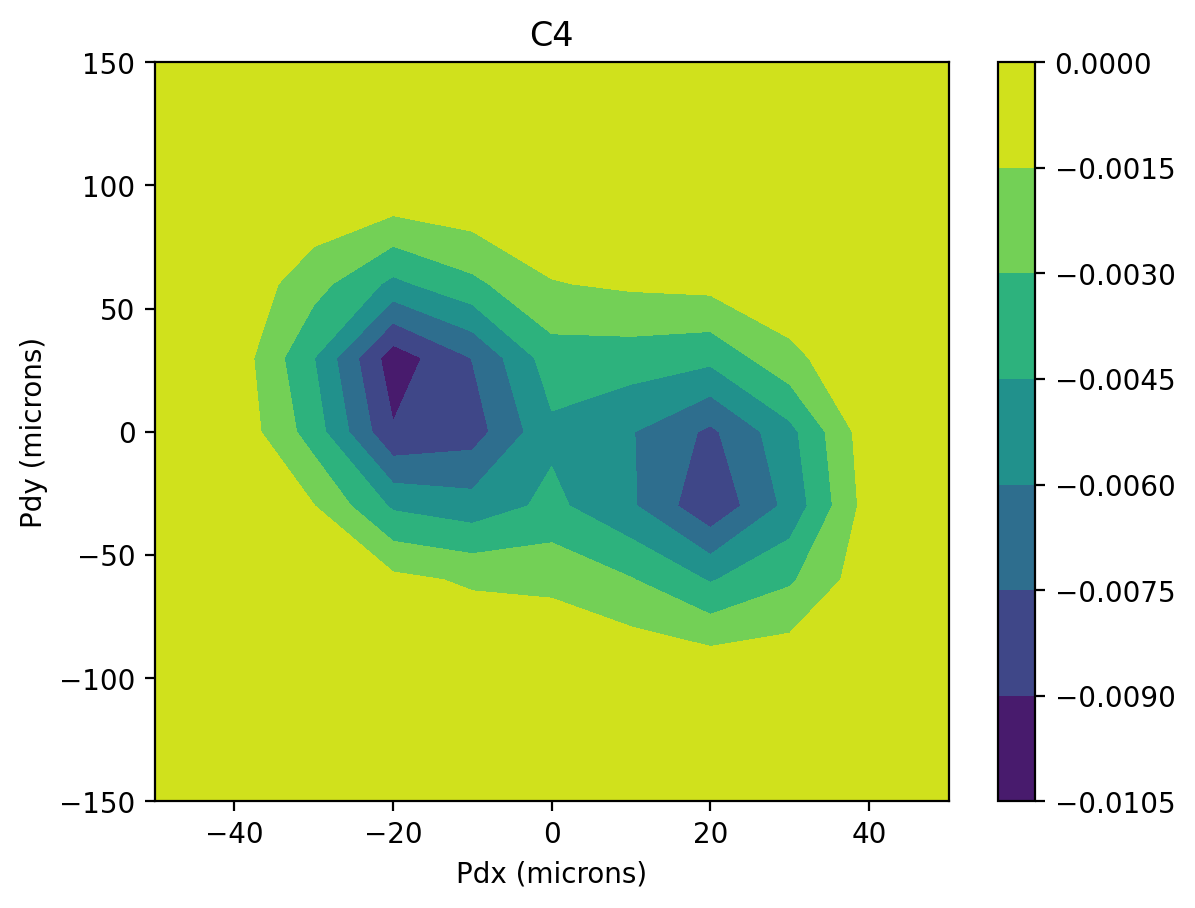

In [223]:
x = np.arange(-50, 60, 10)
y = np.arange(-150, 180, 30)
xx, yy = np.meshgrid(x, y)
vec_genpsf = np.frompyfunc(genpsf, 12, 1)
ars = vec_genpsf(650e-9, xx, yy, 0, 0, 0, 0, 0, 0, 0, 0, 4)
ars = np.array(ars.tolist()).T[3]
h = plt.contourf(x,y,ars)
plt.colorbar()
plt.title("C4")
plt.xlabel("Pdx (microns)")
plt.ylabel("Pdy (microns)")

Text(0, 0.5, 'Pdy (microns)')

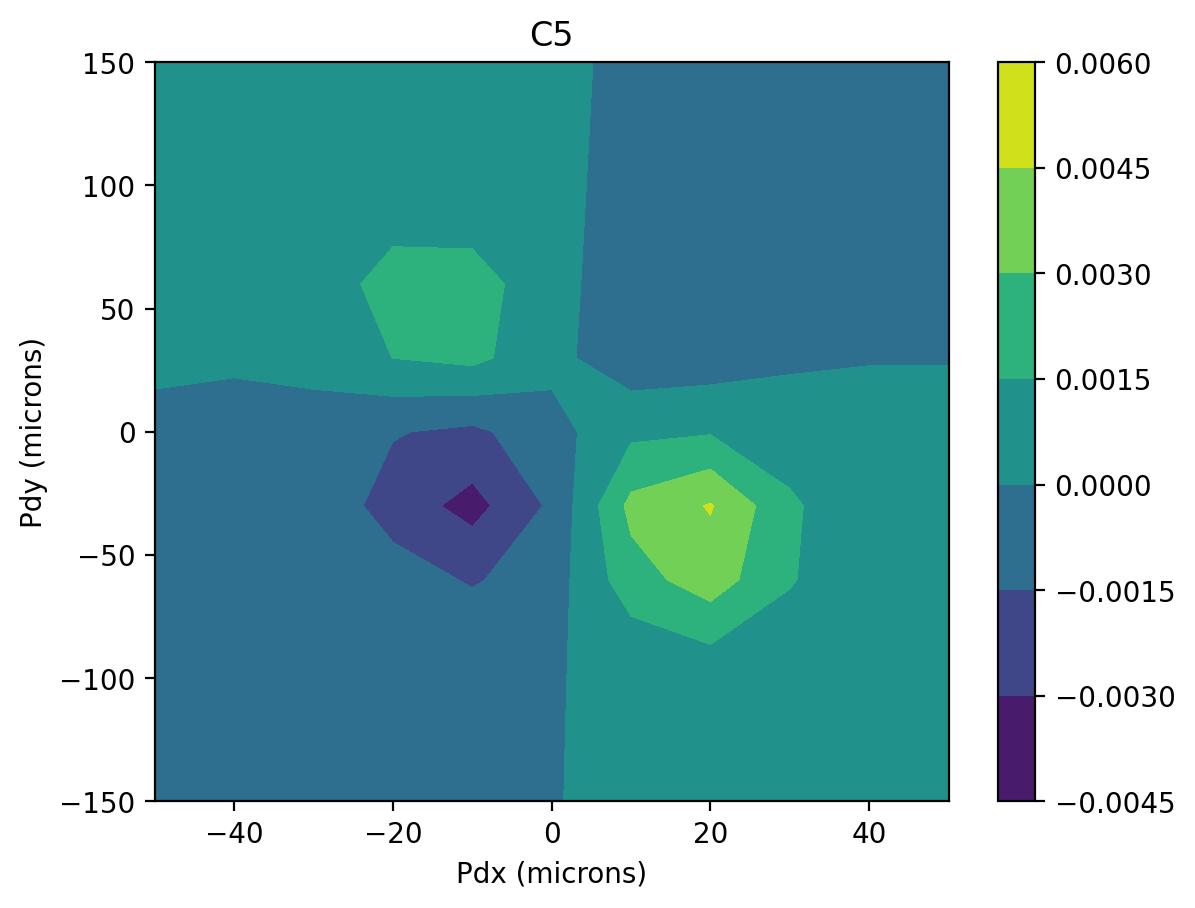

In [222]:
x = np.arange(-50, 60, 10)
y = np.arange(-150, 180, 30)
xx, yy = np.meshgrid(x, y)
vec_genpsf = np.frompyfunc(genpsf, 12, 1)
ars = vec_genpsf(650e-9, xx, yy, 0, 0, 0, 0, 0, 0, 0, 0, 5)
ars = np.array(ars.tolist()).T[4]
h = plt.contourf(x,y,ars)
plt.colorbar()
plt.title("C5")
plt.xlabel("Pdx (microns)")
plt.ylabel("Pdy (microns)")

Text(0, 0.5, 'Pdy (microns)')

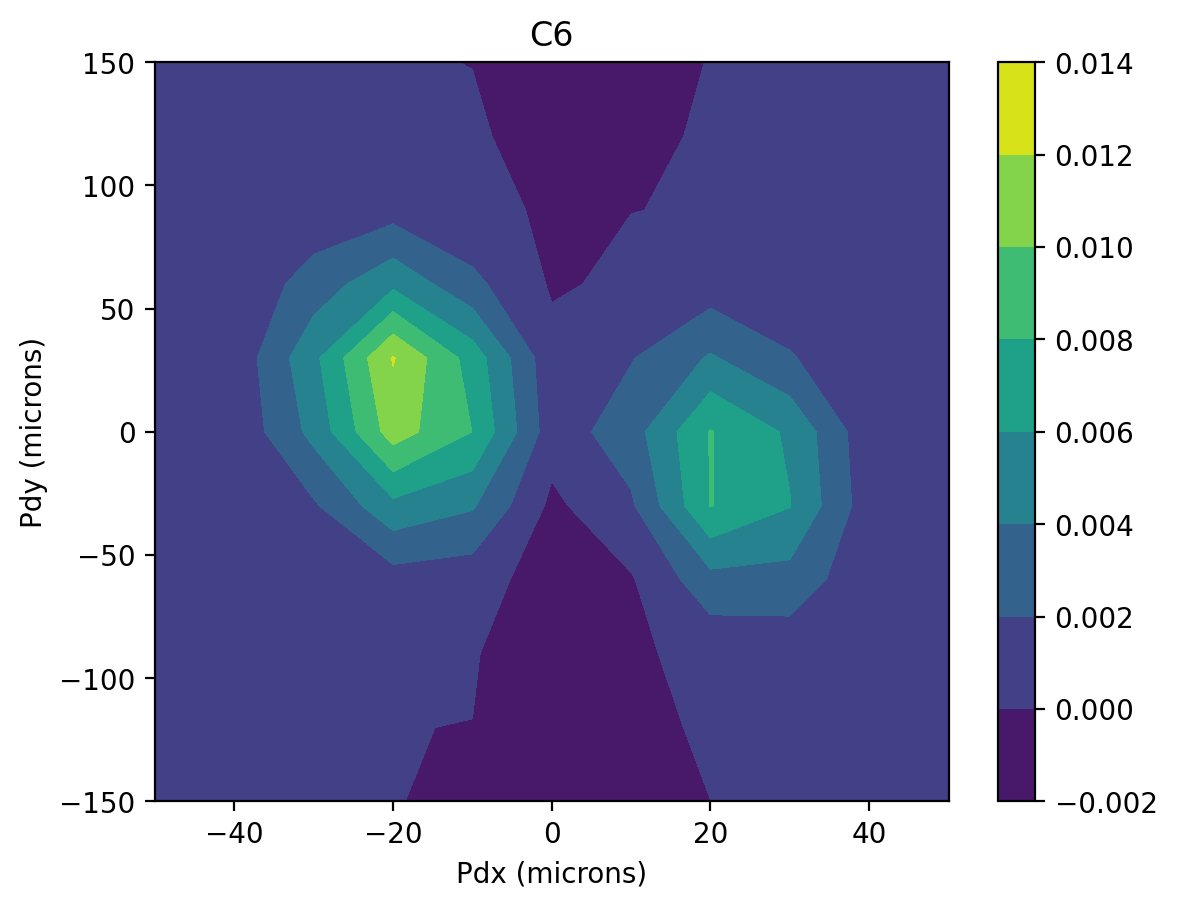

In [227]:
x = np.arange(-50, 60, 10)
y = np.arange(-150, 180, 30)
xx, yy = np.meshgrid(x, y)
vec_genpsf = np.frompyfunc(genpsf, 12, 1)
ars = vec_genpsf(650e-9, xx, yy, 0, 0, 0, 0, 0, 0, 0, 0, 6)
ars = np.array(ars.tolist()).T[5]
h = plt.contourf(x,y,ars)
plt.colorbar()
plt.title("C6")
plt.xlabel("Pdx (microns)")
plt.ylabel("Pdy (microns)")

Text(0, 0.5, 'Pdy (microns)')

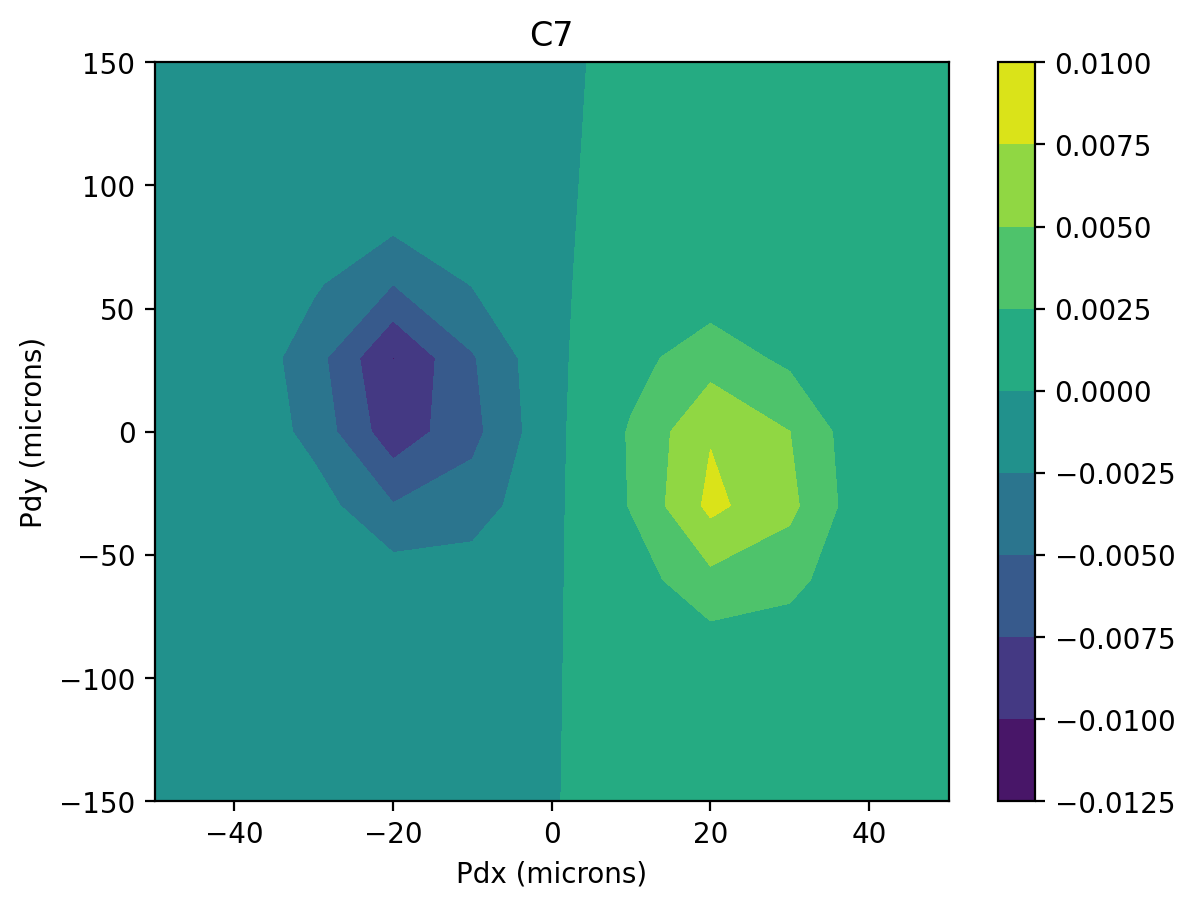

In [228]:
x = np.arange(-50, 60, 10)
y = np.arange(-150, 180, 30)
xx, yy = np.meshgrid(x, y)
vec_genpsf = np.frompyfunc(genpsf, 12, 1)
ars = vec_genpsf(650e-9, xx, yy, 0, 0, 0, 0, 0, 0, 0, 0, 7)
ars = np.array(ars.tolist()).T[6]
h = plt.contourf(x,y,ars)
plt.colorbar()
plt.title("C7")
plt.xlabel("Pdx (microns)")
plt.ylabel("Pdy (microns)")

Text(0, 0.5, 'Pdy (microns)')

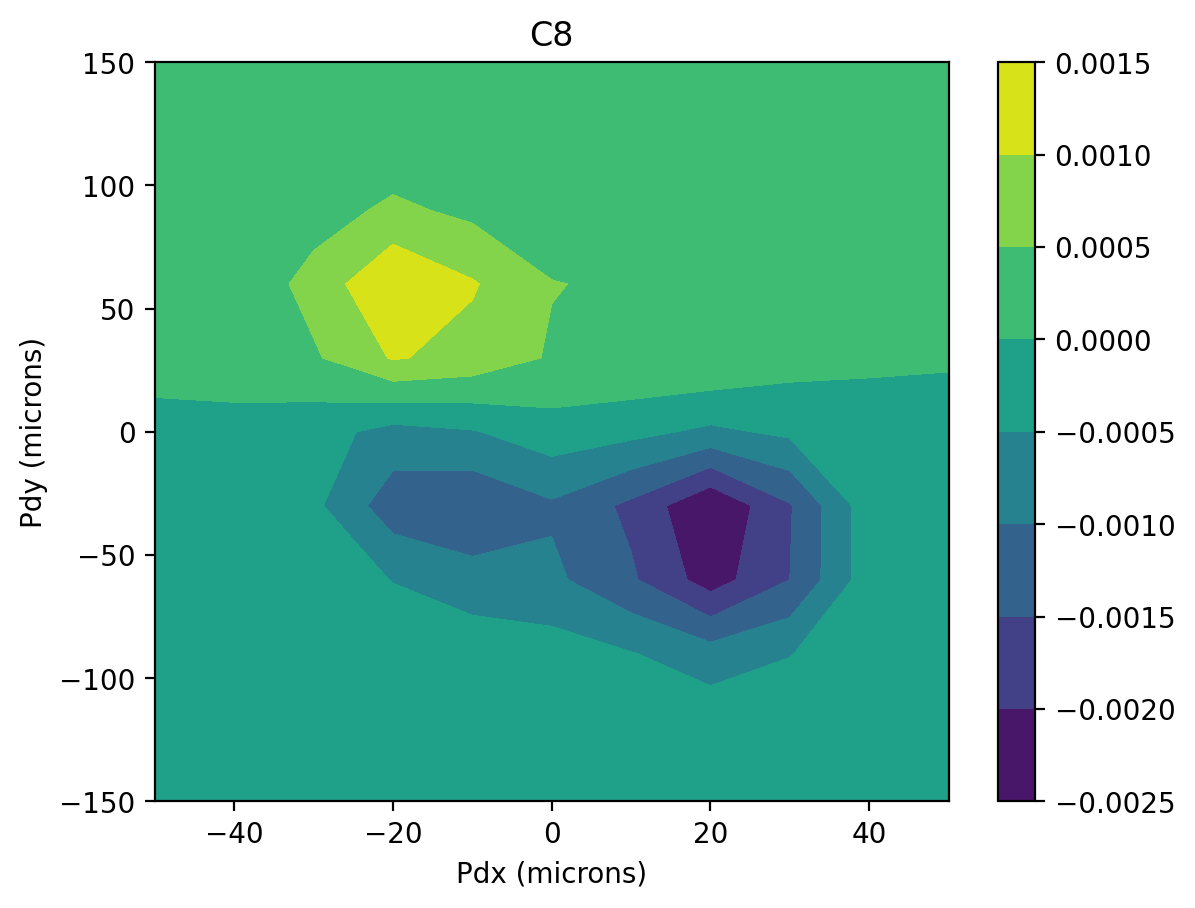

In [229]:
x = np.arange(-50, 60, 10)
y = np.arange(-150, 180, 30)
xx, yy = np.meshgrid(x, y)
vec_genpsf = np.frompyfunc(genpsf, 12, 1)
ars = vec_genpsf(650e-9, xx, yy, 0, 0, 0, 0, 0, 0, 0, 0, 8)
ars = np.array(ars.tolist()).T[7]
h = plt.contourf(x,y,ars)
plt.colorbar()
plt.title("C8")
plt.xlabel("Pdx (microns)")
plt.ylabel("Pdy (microns)")

Text(0, 0.5, 'Pdy (microns)')

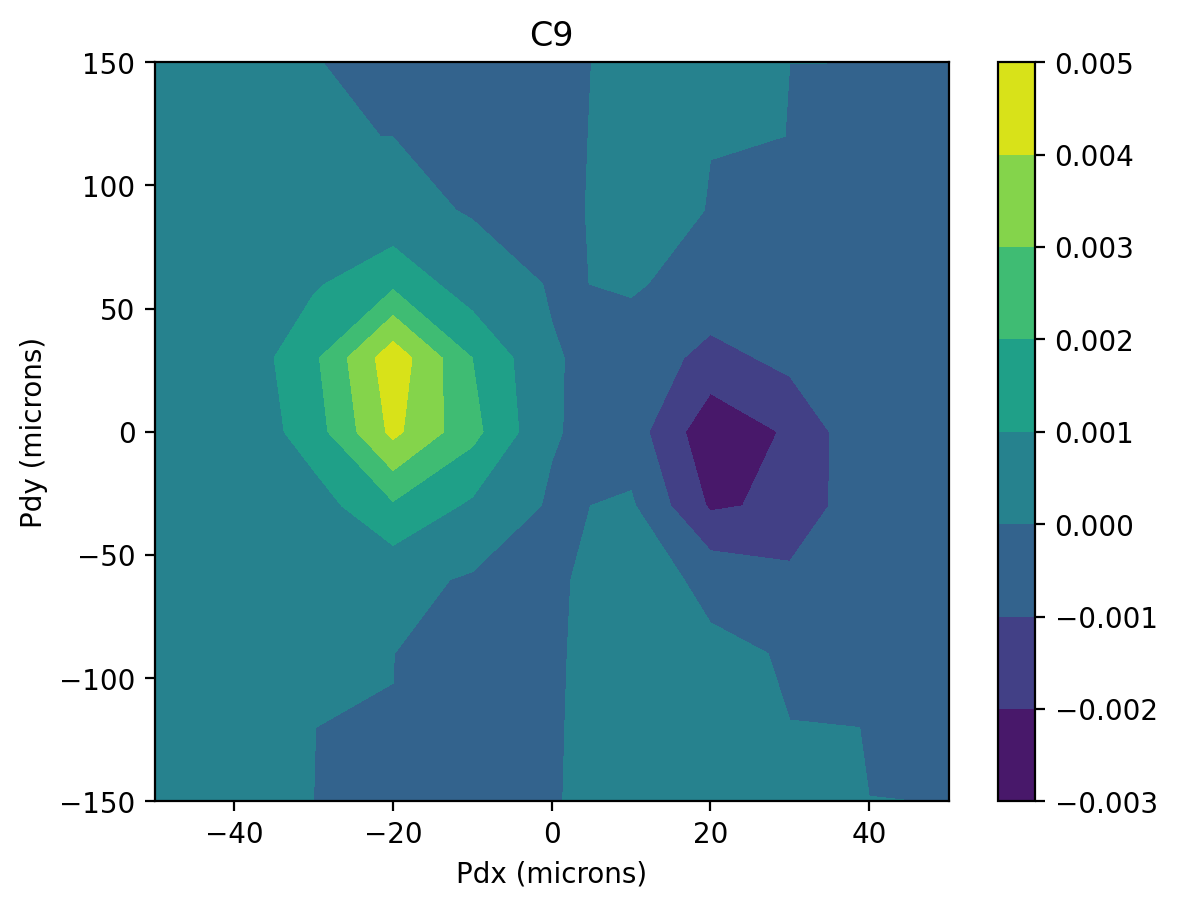

In [230]:
x = np.arange(-50, 60, 10)
y = np.arange(-150, 180, 30)
xx, yy = np.meshgrid(x, y)
vec_genpsf = np.frompyfunc(genpsf, 12, 1)
ars = vec_genpsf(650e-9, xx, yy, 0, 0, 0, 0, 0, 0, 0, 0, 9)
ars = np.array(ars.tolist()).T[8]
h = plt.contourf(x,y,ars)
plt.colorbar()
plt.title("C9")
plt.xlabel("Pdx (microns)")
plt.ylabel("Pdy (microns)")

Text(0, 0.5, 'Pdy (microns)')

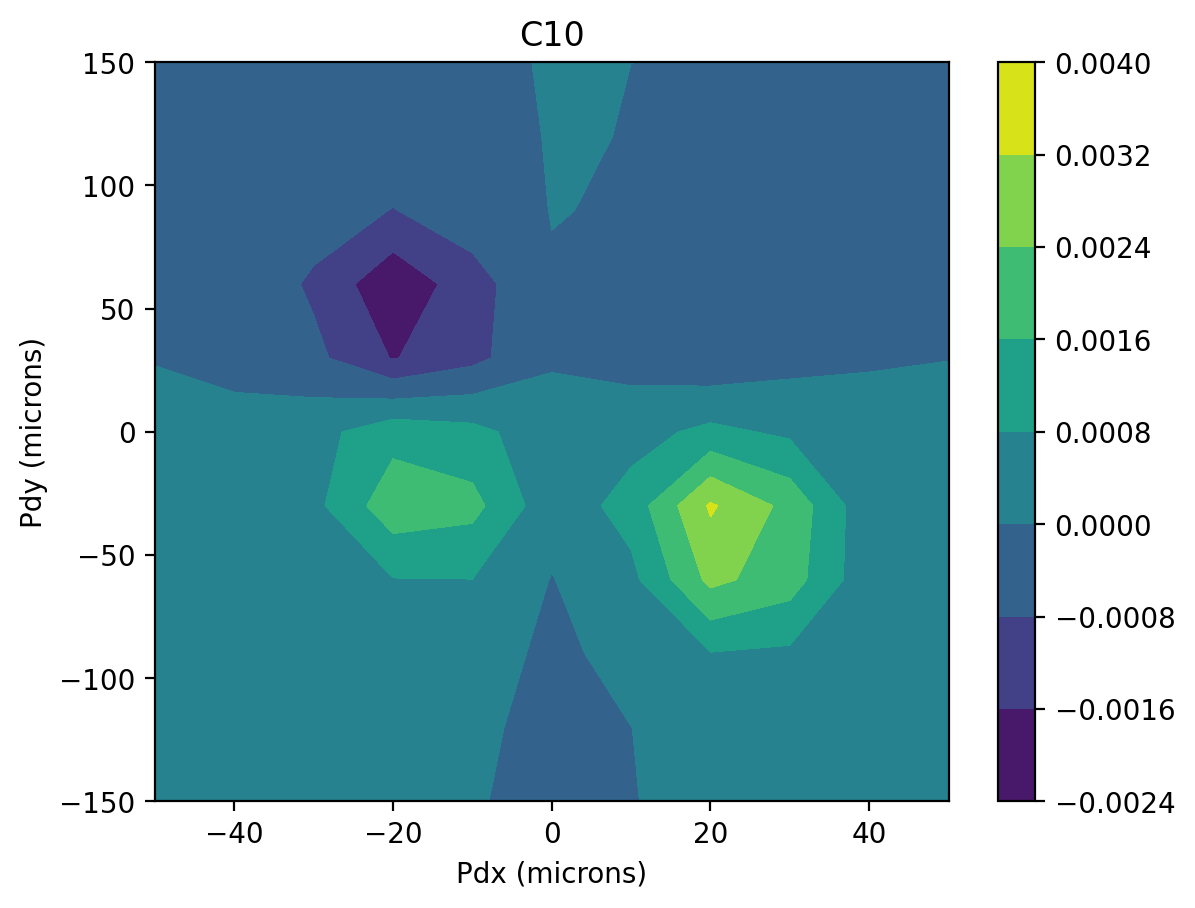

In [231]:
x = np.arange(-50, 60, 10)
y = np.arange(-150, 180, 30)
xx, yy = np.meshgrid(x, y)
vec_genpsf = np.frompyfunc(genpsf, 12, 1)
ars = vec_genpsf(650e-9, xx, yy, 0, 0, 0, 0, 0, 0, 0, 0, 10)
ars = np.array(ars.tolist()).T[9]
h = plt.contourf(x,y,ars)
plt.colorbar()
plt.title("C10")
plt.xlabel("Pdx (microns)")
plt.ylabel("Pdy (microns)")

In [108]:
x = np.arange(-5, 15, 1)
y = np.arange(-135, 140, 5)
xx, yy = np.meshgrid(x, y)
#vec_genpsf = np.frompyfunc(genpsf, 12, 1)
ars = vec_genpsf(650e-9, xx, yy, 0, 0, 0, 0, 0, 0, 0, 0, 11)
ars = np.array(ars.tolist()).T[10]

In [109]:
x.shape, y.shape, ars.shape

((20,), (55,), (20, 55))

Text(0, 0.5, 'Pdy (microns)')

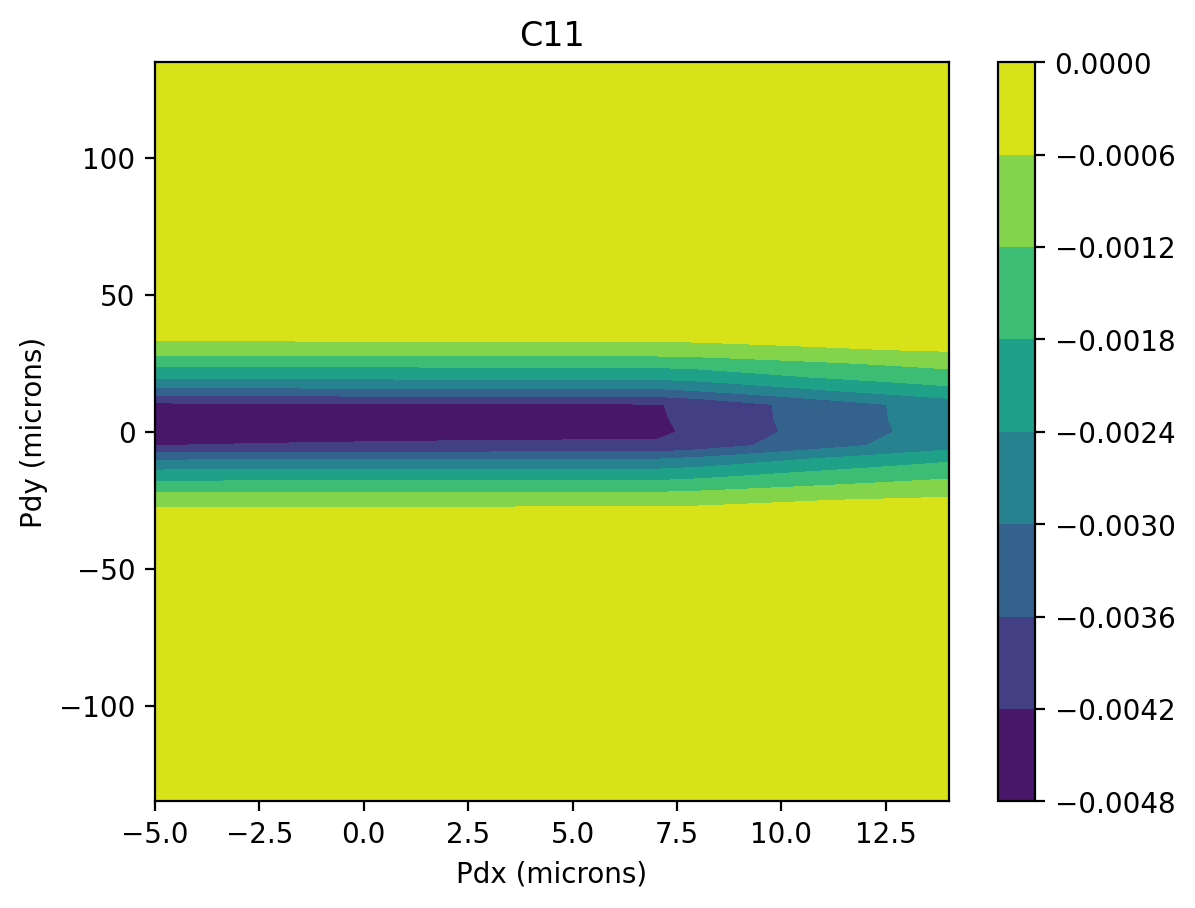

In [111]:
h = plt.contourf(x,y,ars.T)
plt.colorbar()
plt.title("C11")
plt.xlabel("Pdx (microns)")
plt.ylabel("Pdy (microns)")

# Look at this later (or never)

In [ ]:
from itertools import product

In [ ]:
def schwiegerling_basis(n, m, pn, pm, npix=100, rho=None, theta=None, **kwargs):
    """Return the Schwiegerling PSF basis function."""

    if theta is None and rho is None:
        x = (np.arange(npix, dtype=np.float64) - (npix - 1.) / 2.) / ((npix - 1) / 2.)
        y = x
        xx, yy = np.meshgrid(x, y)

        rho = np.sqrt(xx ** 2 + yy ** 2)
        theta = np.arctan2(yy, xx)
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")
        
    if not np.all(np.asarray(rho.shape == theta.shape)):
        raise ValueError('The rho and theta arrays do not have consistent shape.')

    aperture = (rho <= 20)

    if m - pm == 0:
        result = (-1)**((n-pn)/2) * jv(n+1, 2*np.pi*rho) * (1/rho) * jv(pn+1, 2*np.pi*rho) * (1/rho)

    elif _is_odd(m - pm) == 1:
        result = 2 * (-1)**((n-pn+1)/2) * jv(n+1, 2*np.pi*rho) * (1/rho) * jv(pn+1, 2*np.pi*rho) * (1/rho) * np.sin((m-pm) * theta)

    else:
        result = 2 * (-1)**((n-pn)/2) * jv(n+1, 2*np.pi*rho) * (1/rho) * jv(pn+1, 2*np.pi*rho) * (1/rho) * np.cos((m-pm) * theta)

    return result

In [ ]:
def gs_schwiegerling(basis=basis_vectors(nterms=15), npix=256):
    basis_output = np.zeros((len(basis),) + (npix, npix))

    for k in range(len(basis)):
        if k == 0:
            basis_output[k] = basis[k]
        elif k == 1:
            basis_output[k] = basis[k] - (np.vdot(basis[k], basis[0])/(np.vdot(basis[0],basis[0])))*basis[0]
        else:
            for j in range(k-1):
                b = basis[k]
                b -= (np.vdot(b, basis[j])/(np.vdot(basis[j],basis[j])))*basis[j]
                basis_output[k] = b

    return basis_output

In [ ]:
def schwiegerling_basis1(j, **kwargs):
    n, m, pn, pm = indices[j][0],indices[j][1],indices[j][2],indices[j][3]
    return (1/np.pi**2)*schwiegerling_basis(n, m, pn, pm, **kwargs)   

In [ ]:
def gs_schwiegerling_basis1(j, **kwargs):

    if j == 0:
        out = schwiegerling_basis1(0)

    elif j == 1:
        out = schwiegerling_basis1(j) - (np.vdot(schwiegerling_basis1(j), schwiegerling_basis1(0))/(np.vdot(schwiegerling_basis1(0),schwiegerling_basis1(0))))*schwiegerling_basis1(0)

    else:
        for k in range(j+1):
            for i in range(k):
                o = schwiegerling_basis1(k)
                o -= (np.vdot(o, schwiegerling_basis1(i))/(np.vdot(schwiegerling_basis1(i),schwiegerling_basis1(i))))*schwiegerling_basis1(i)
                out = o
    out = out/np.linalg.norm(out)

    return out

In [ ]:
def nmj(j):
    n = math.ceil(-3/2 + math.sqrt(9+8*(j))/2)
    m = 2*(j) - n*(n + 2)
    return n, m

In [ ]:
order = 2
rws = int(((order+1)*((order+1)+1)/2)**2)
ol = list(product(sb(order), sb(order)))
numpy_array = np.array(ol)
reshaped_array = numpy_array.reshape(rws, 4)

In [ ]:
def mdiff(arr):
    m = arr[:, 1]
    pm = arr[:, 3]
    return(m - pm)

In [ ]:
mdiff(reshaped_array)

array([ 0,  1, -1,  2,  0, -2, -1,  0, -2,  1, -1, -3,  1,  2,  0,  3,  1,
       -1, -2, -1, -3,  0, -2, -4,  0,  1, -1,  2,  0, -2,  2,  3,  1,  4,
        2,  0])

In [ ]:
for i in range(len(mdiff(reshaped_array))):
    if _is_odd(mdiff(reshaped_array)[i]) == 0 and mdiff(reshaped_array)[i] != 0:
        print(i)

3
5
8
13
18
22
23
27
29
30
33
34


In [ ]:
def schwiegerling_basis1(j, **kwargs):
    n, m, pn, pm = indices[j][0],indices[j][1],indices[j][2],indices[j][3]
    return (1/np.pi**2)*schwiegerling_basis(n, m, pn, pm, **kwargs)   

In [ ]:
psf = (1/np.pi**2)*(0.63662*0.63662*schwiegerling_basis(n=0,m=0,pn=0,pm=0, npix=256)+1.21585*1.21585*schwiegerling_basis(n=2,m=0,pn=2,pm=0, npix=256)+0.68708*0.68708*schwiegerling_basis(n=4,m=0,pn=4,pm=0, npix=256)+0.63662*1.21585*schwiegerling_basis(n=0,m=0,pn=2,pm=0, npix=256)+0.63662*0.68708*schwiegerling_basis(n=0,m=0,pn=4,pm=0, npix=256)+1.21585*0.68708*schwiegerling_basis(n=2,m=0,pn=4,pm=0, npix=256))

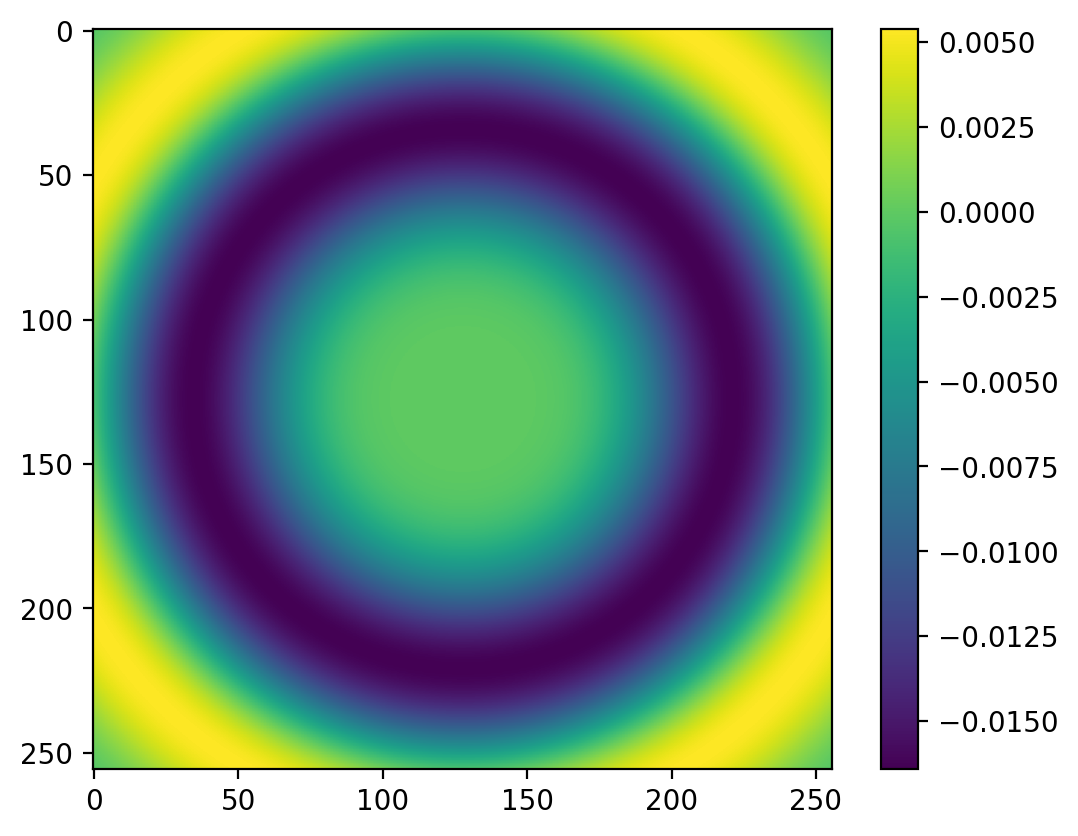

In [ ]:
plt.imshow((1/np.pi**2)*schwiegerling_basis(2, 0, 4, 0, npix=256))
plt.colorbar()

In [ ]:
indices = np.array([[0,0,0,  0],
[0,0,1, -1],
[1,-1,1,-1],
[1,-1,1, 1],
[0,0,2, -2],
[0,0,2,  0],
[1,-1,2,-2],
[1,-1,2, 2],
[2,-2,2,-2],
[2,-2,2, 0],
[2,-2,2, 2],
[0,0,3, -3],
[0,0,3, -1],
[1,-1,3,-3],
[1,-1,3,-1],
[1,-1,3, 3],
[2,-2,3,-3],
[2,-2,3, 1],
[2,-2,3, 3],
[3,-3,3,-3],
[3,-3,3,-1],
[3,-3,3, 1],
[3,-3,3, 3],
[0,0,4, -4],
[0,0,4, -2],
[0,0,4,  0],
[1,-1,4,-4],
[1,-1,4,-2],
[1,-1,4, 4],
[2,-2,4,-4],
[2,-2,4,-2],
[2,-2,4, 2],
[2,-2,4, 4],
[3,-3,4,-4],
[3,-3,4, 0],
[3,-3,4, 2],
[3,-3,4, 4],
[4,-4,2, 0],
[4,-4,2, 2],
[4,-4,4,-4],
[4,-4,4,-2],
[4,-4,4, 0],
[4,-4,4, 2],
[4,-4,4, 4]])

In [ ]:
def nmj(jk):
    if _is_odd(jk):
        j = (jk//2)
        n = math.ceil(-3/2 + math.sqrt(9+8*(j))/2)
        m = 2*(j) - n*(n + 2)
        pn = math.ceil(-3/2 + math.sqrt(9+8*(j+2))/2)
        pm = 2*(j+2) - pn*(pn + 2)
        return n, m, pn, pm
    else:
        j = int(jk/2)
        n = math.ceil(-3/2 + math.sqrt(9+8*j)/2)
        m = 2*j - n*(n + 2)
        pn = math.ceil(-3/2 + math.sqrt(9+8*(j+1))/2)
        pm = 2*(j+1) - pn*(pn + 2)
        return n, m, pn, pm

In [ ]:
nmj(24)

(4, 0, 4, 2)

In [ ]:
def nmj(j):
    n = math.ceil(-3/2 + math.sqrt(9+8*(j))/2)
    m = 2*(j) - n*(n + 2)
    return n, m

In [ ]:
def seqgen(jmax):
    for j in range(jmax):
        for k in range(jmax):
            k = j+1
            pn = nmj(k)[0]
            pm = nmj(k)[1]
        n = nmj(j)[0]
        m = nmj(j)[1]
        print(n,m,pn,pm)

In [ ]:
psf = 0.405*schwiegerling_basis1(0, npix=128)+1.478*schwiegerling_basis1(8, npix=128)+0.774*schwiegerling_basis1(39, npix=128)+0.437*schwiegerling_basis1(25, npix=128)+0.835*schwiegerling_basis1(30, npix=128)

In [ ]:
psf = gs_schwiegerling_basis1(0)+gs_schwiegerling_basis1(8)+gs_schwiegerling_basis1(39, npix=128)+gs_schwiegerling_basis1(25, npix=128)+gs_schwiegerling_basis1(30, npix=128)

In [ ]:
np.vdot(gs_schwiegerling_basis1(5, npix=128), gs_schwiegerling_basis1(0, npix=128))

-0.5842640687895717

In [ ]:
for i in range(15):
    print(np.vdot(psf, gs_schwiegerling_basis1(i, npix=128))/(np.vdot(gs_schwiegerling_basis1(i, npix=128),gs_schwiegerling_basis1(i, npix=128))))

1.1966666732310307
-1.933336820240175e-17
1.2497968679560911
-1.0441903544760862e-15
3.346441539763284e-16
-1.2987113340903287
5.434343690412887e-17
3.01556170018942e-17
0.556282116385598
1.710251104101685e-16
-0.03418503431201676
4.276457592450142e-18
-8.459106285991861e-18
1.4151368712796773e-15
-0.7136564304537278


In [ ]:
np.linalg.det(schwiegerling_basis1(10))

0.0

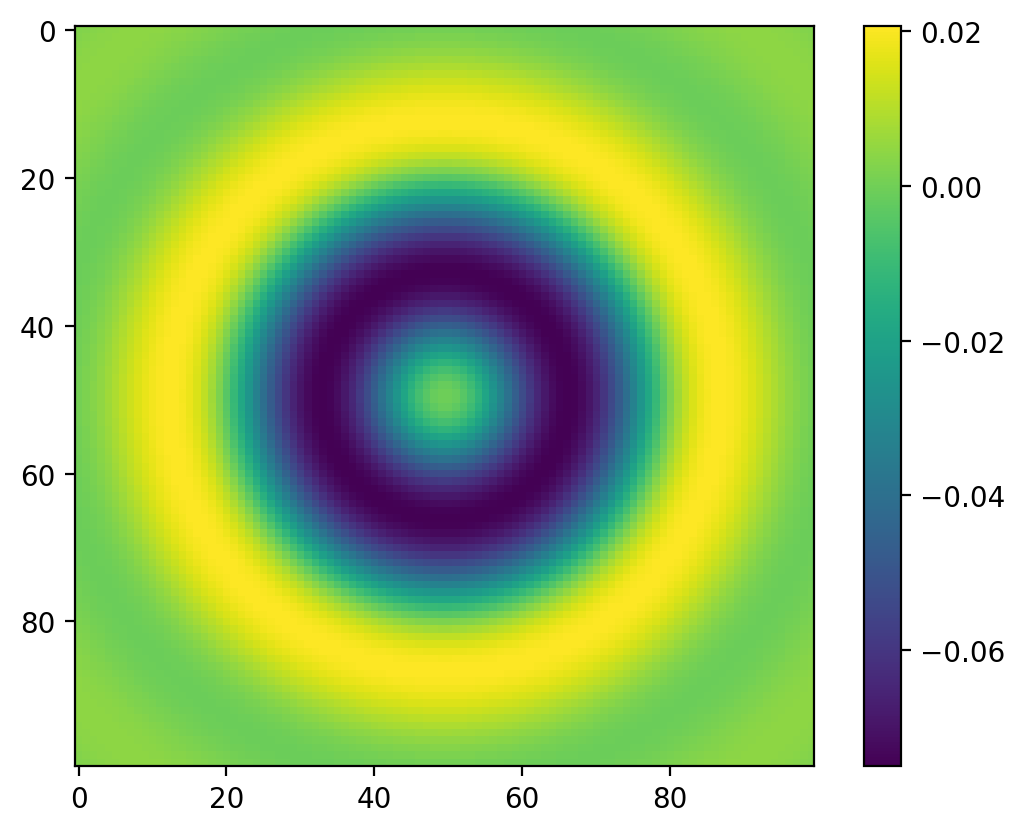

In [ ]:
plt.imshow(schwiegerling_basis1(5))
plt.colorbar()

In [ ]:
HST_data = {
    'M1': {
        'Radius': 11040.,
        'Conic': -1.0022985,
        'Aperture': 2 * 1200.,
        'Obscuration':{
            'Inner': 2 * 350.,
            'Arm size': 25.,
            'Arm number': 4
        }
    },
    'M2': {
        'Radius': 1358.,
        'Conic': -1.49600,
        'Aperture': 2 * 150.
    },
    'Spacings': {
        'BFD': 1500.,
        'Separation': 4906.072
    }
}

def telescopeCreation(WL, dx, dy, dz, tx, ty, tz):
    #global WL
    global telescope, M1

    global outter1, inner1, outterD
    
    K = 1000 #meter conversion from mm
        ##############################

        ### Primary ###
    R1, conic1, inner1, outter1 = -HST_data['M1']['Radius']/K, HST_data['M1']['Conic'], HST_data['M1']['Obscuration']['Inner']/K, HST_data['M1']['Aperture']/K
    M1coord = defineCoordinate().local()
    M1 = optic('M1', type='Quadric', RoC=R1, conic=conic1, inDiam=inner1, outDiam=outter1, coordSys=M1coord).mirrorWithSpider(4, 0.025)
        ###############

        ### Seconday ###
    R2, conic2, outter2 = -HST_data['M2']['Radius']/K, HST_data['M2']['Conic'], HST_data['M2']['Aperture']/K
    pos2 = -HST_data['Spacings']['Separation']/K
    M2coord = defineCoordinate(posX=dx/K, posY=dy/K, posZ=pos2+dz/K, anglX=tx, anglY=ty, anglZ=tz).local()
    M2 = optic('M2', type='Quadric', RoC=R2, conic=conic2, outDiam=outter2, coordSys=M2coord).mirror()
        ################

        ### Detector ###
    outterD = 1
    posD = HST_data['Spacings']['BFD']/K
    Dcoord = defineCoordinate(posZ=posD).local()
    D = optic('D', outDiam=outterD, coordSys=Dcoord).detector()
        ################

        ### HST ###
    telescope = build.compoundOptic(M1, M2, D,
                                   pupilSize=outter1, backDist=6,
                                   EPcoord=defineCoordinate(posZ=0).local())
    
    return telescope

In [ ]:
def showPSF(WL):  
    start = time.time()
    
    ## FFT PSF
    fieldX, fieldY = 0/3600, 50/3600

    pad = 16
    
    infoTelescope = details(telescope, fieldX=fieldX, fieldY=fieldY, wavelength=WL)
    PSF, StehlRatio = infoTelescope.fftPSF(npx=128, pad=pad) # pad: pixelization / npx: accuracy

    ## PSF Plot
    plot.psf2D(PSF, infoTelescope.airyRadius())

    print('\nPSF calculation+plot time', np.round(time.time()-start, decimals=5))

In [ ]:
def showSpotDiagram(WL, fieldX=0, fieldY=0):
    ## Incoming rays
    nbOfRays = 1e4
    fieldY += fieldBias
    rays0 = ray(telescope, fieldX=fieldX, fieldY=fieldY, wavelength=WL, nbOfRays=nbOfRays).fromPupil(type='grid')
    rays = rays0.copy()

    ## Trace rays + deleting vignetted ones
    telescope.trace(rays, reverse=False)
    rays = ray.deleteVignettedRays(rays)
    
    ## Some details
    infoTelescope = details(telescope, fieldX=fieldX, fieldY=fieldY, wavelength=WL)
    print('F/# in Image Space     :', np.round(infoTelescope.paraxialWorkingFNumber(), decimals=5))
    print('Paraxial Working F/#   :', np.round(infoTelescope.FNumber(), decimals=5))
    print('Working F/#            :', np.round(infoTelescope.workingFNumber(offFieldY=fieldBias), decimals=5))
    print('NA in Image Space      :', np.round(infoTelescope.NA(), decimals=8))
    print('Effective Focal Length :', -np.round(infoTelescope.EFFL() * 1000, decimals=2), 'mm')
    print('XP position            :', np.round(batoid.analysis.exitPupilPos(optic=telescope, wavelength=WL)[-1]-telescope.items[-1].coordSys.origin[-1], decimals=6) * 1000, 'mm')
    print('Airy radius            :', np.round(airyR:=infoTelescope.airyRadius(offFieldY=fieldBias), decimals=4), 'µm')
    print('Out/In Flux            :', np.round(np.sum(rays.flux)/np.sum(rays0.flux)*100, decimals=2), '%')
    print('Strehl Ratio           :', np.round(infoTelescope.strehlRatio(), decimals=4))

    ## Plot Spot Diagram
    #return spotDiagram(rays0, fieldBias, rays, WL, airyR=airyR, scale=40)
    plot.spotDiagram(rays0, fieldBias, rays, WL, airyR=airyR, scale=40)

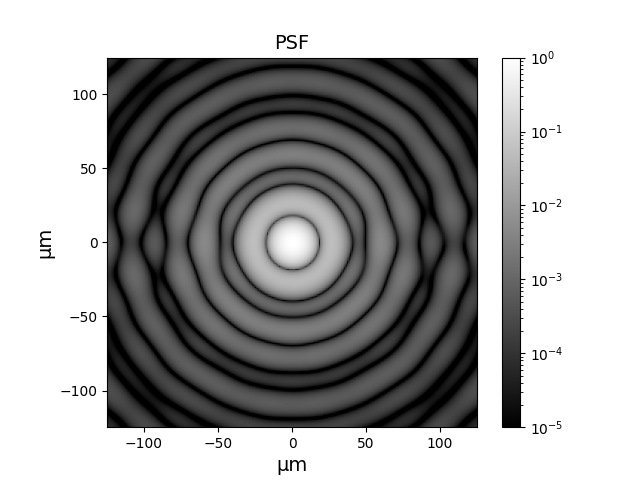


PSF calculation+plot time 0.7837
F/# in Image Space     : 24.00051
Paraxial Working F/#   : 23.99959
Working F/#            : 23.91817
NA in Image Space      : 0.02083289
Effective Focal Length : -57599.01 mm
XP position            : -7002.523 mm
Airy radius            : 18.962 µm
Out/In Flux            : 90.15 %
Strehl Ratio           : 0.0


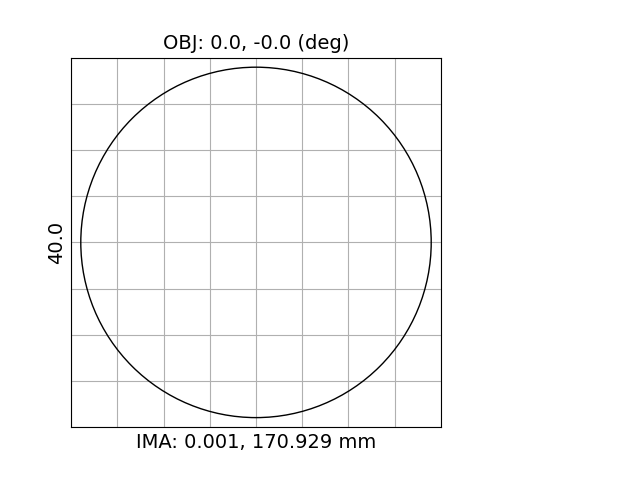

08/26/2025
Units are µm. Airy Radius: 18.962 µm. Wavelength: 0.65 µm.
RMS radius :    356.757
GEO radius :    521.523
Scale bar  :   40.0    Reference : Centroid



In [ ]:
WL = 650e-9
def main():
    %run Batoid4LOFT.ipynb

    plt.close('all')

    global fieldBias
    #fieldBias = 0.0 #Strehl ratio = 0.867

    telescopeCreation(WL, dx=0, dy=0, dz=0, tx=0, ty=0, tz=0)

    ## Select what you want to see
    showPSF(WL)
    showSpotDiagram(WL, fieldX=0, fieldY=0)

if __name__=='__main__':
    main()

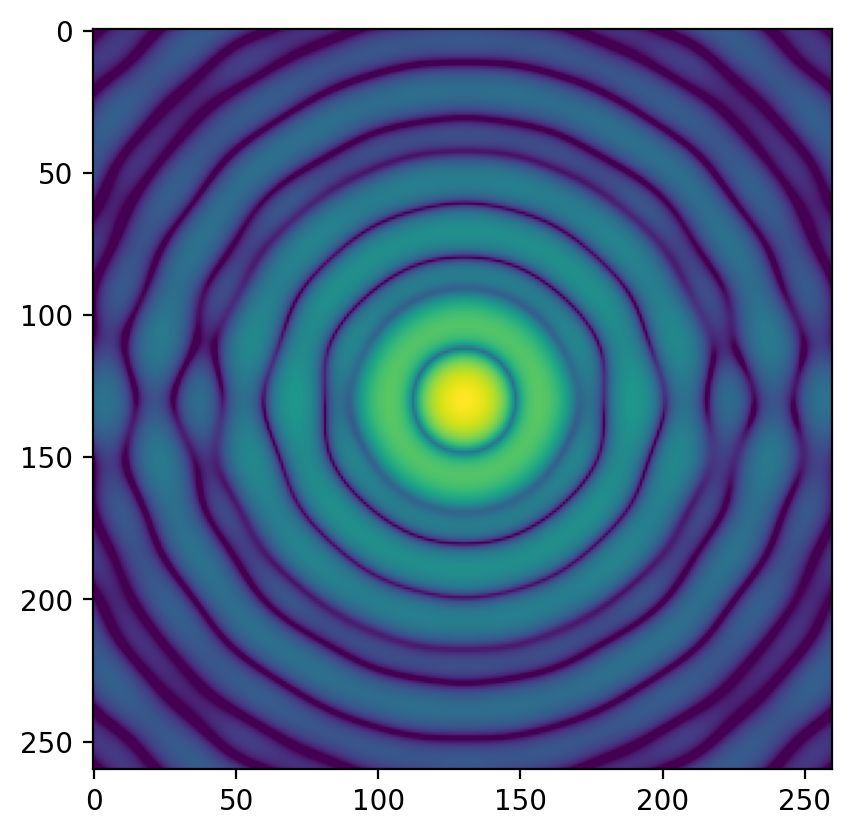

In [ ]:
%matplotlib inline

telescope1 = telescopeCreation(WL, dx=0, dy=0, dz=0, tx=0, ty=0, tz=0)
infoTelescope = details(telescope1, fieldX=0, fieldY=0, wavelength=WL)
PSF1, StehlRatio = infoTelescope.fftPSF(npx=128, pad=16)
plt.imshow(PSF1[894:1154,894:1154], norm=mcolors.LogNorm(vmin=1e-5, vmax=1))
plt.show()

In [ ]:
infoTelescope.airyRadius()*plot.findPxSize(PSF1[894:1154,894:1154], infoTelescope.airyRadius())

19.053609871416903

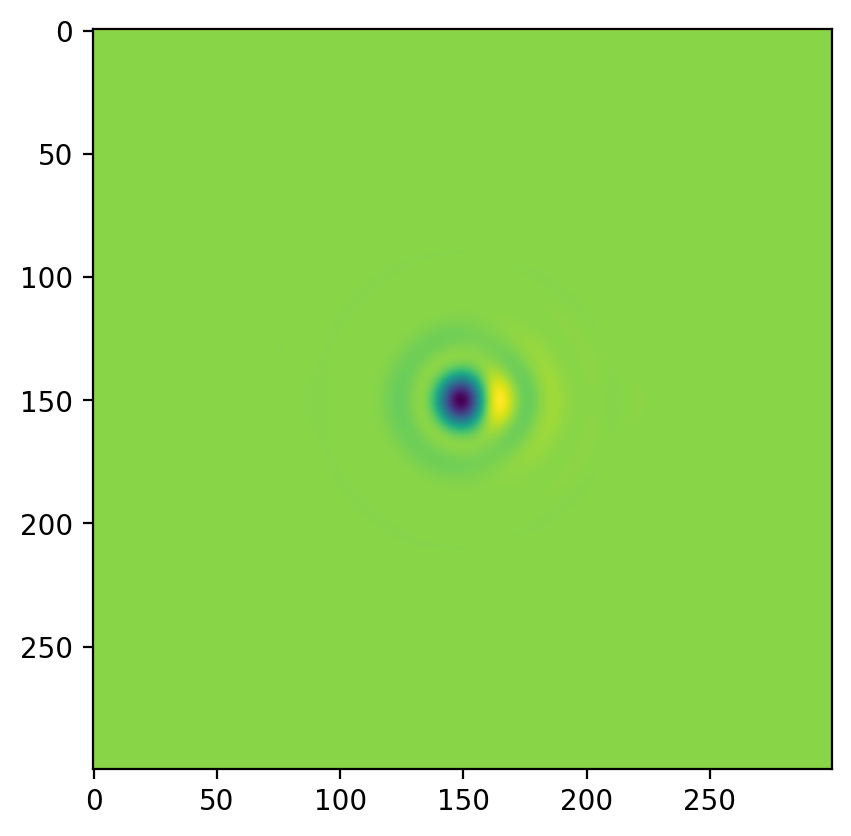

In [ ]:
%matplotlib inline
plt.imshow(PSF2[874:1174,874:1174]-PSF1[874:1174,874:1174])
plt.show()

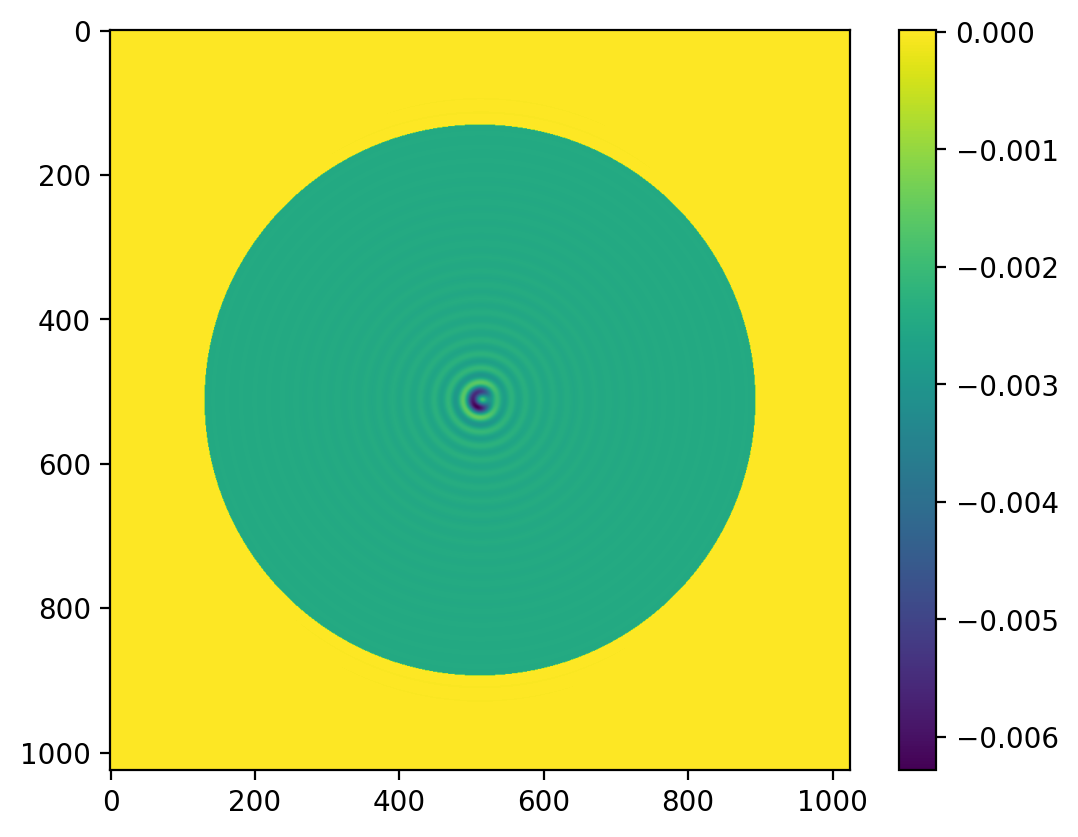

In [ ]:
e = poppy.zernike.decompose_opd_nonorthonormal_basis(PSF2[874:1174,874:1174]-PSF1[874:1174,874:1174], basis=basis_vectors)
plt.imshow(poppy.zernike.compose_opd_from_basis(e, npix=1024, basis=basis_vectors))
plt.colorbar()

In [ ]:
e

array([-2.45078261e-03, -1.21994958e-03,  4.37248738e-04,  3.56348980e-03,
       -6.76689760e-05, -8.82235303e-04,  1.29105195e-04, -9.28674851e-04,
       -5.45822208e-05, -3.16493054e-04,  3.17243539e-04, -3.91494980e-04,
       -3.85257230e-05, -1.05020978e-04, -2.15038715e-05])

In [ ]:
telescope1 = telescopeCreation(WL, dx=0.1, dy=0.0, dz=0.0, tx=0.0, ty=0.0, tz=1)
infoTelescope = details(telescope1, fieldX=0, fieldY=0, wavelength=WL)
PSF2, StehlRatio = infoTelescope.fftPSF(npx=128, pad=16)
plt.imshow(PSF2[894:1154,894:1154], norm=mcolors.LogNorm(vmin=1e-5, vmax=1))

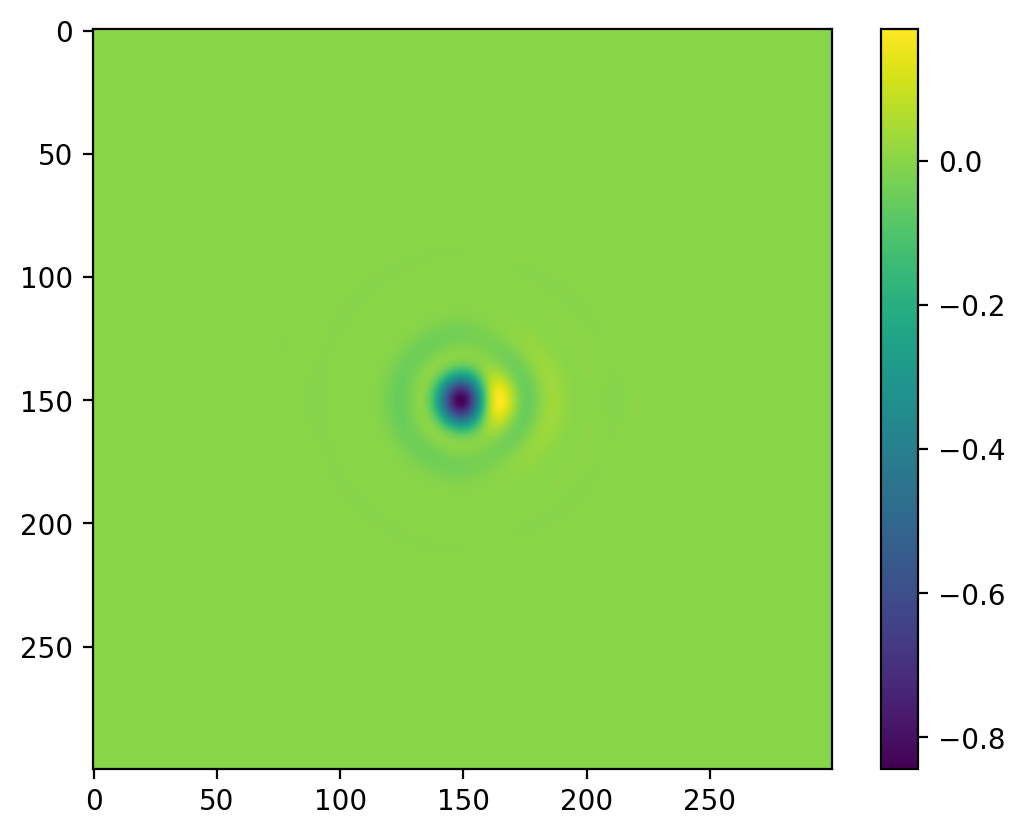

In [ ]:
plt.imshow(PSF2[874:1174,874:1174]-PSF1[874:1174,874:1174])
plt.colorbar()

In [ ]:
def norm_data(data):
    """
    normalize data to have mean=0 and standard_deviation=1
    """
    mean_data=np.mean(data)
    std_data=np.std(data, ddof=1)
    #return (data-mean_data)/(std_data*np.sqrt(data.size-1))
    return (data-mean_data)/(std_data)


def ncc(data0, data1):
    """
    normalized cross-correlation coefficient between two data sets

    Parameters
    ----------
    data0, data1 :  numpy arrays of same size
    """
    return (1.0/(data0.size-1)) * np.sum(norm_data(data0)*norm_data(data1))

In [ ]:
ncc(PSF1,PSF2)

1.0000000000000009

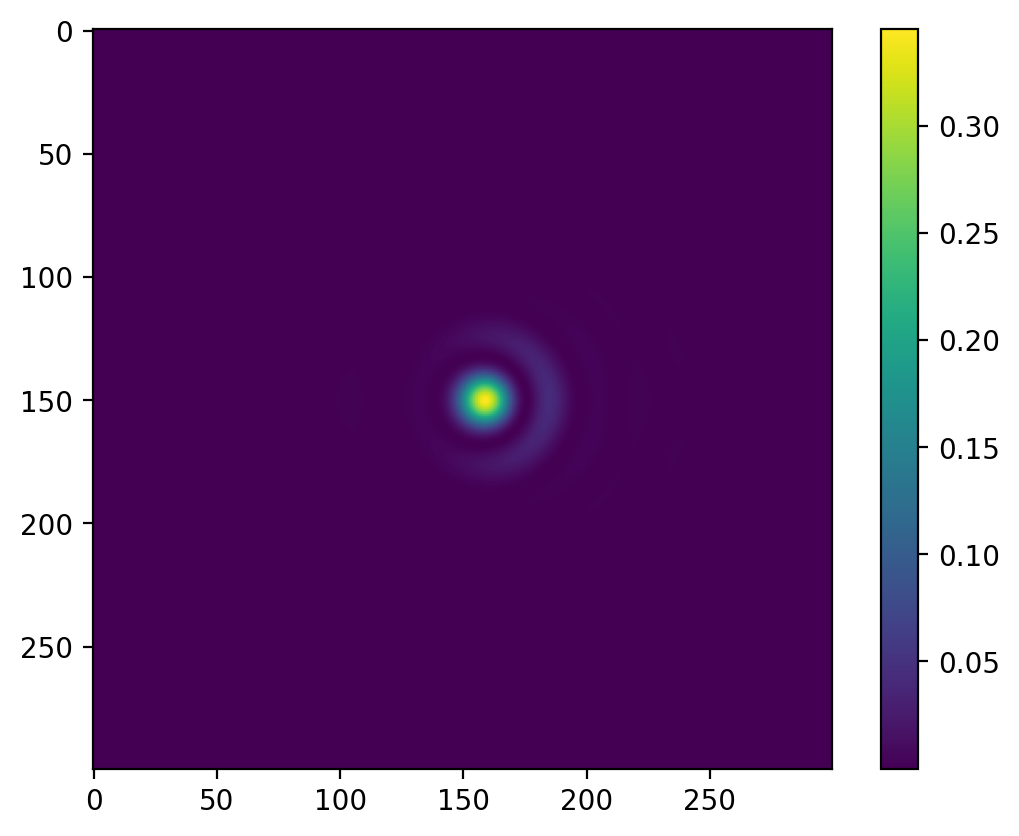

In [ ]:
plt.imshow(PSF2[874:1174,874:1174])
plt.colorbar()

In [ ]:
x_solve = np.linalg.solve(PSF1, PSF2)

In [ ]:
def get_klip_basis(R, cutoff):
    '''
    Succinct KLIP implementation courtesy of N. Zimmerman
    '''
    w, V = np.linalg.eig(np.dot(R, np.transpose(R)))
    sort_ind = np.argsort(w)[::-1] #indices of eigenvals sorted in descending order
    sv = np.sqrt(w[sort_ind]).reshape(-1,1) #column of ranked singular values
    Z = np.dot(1./sv*np.transpose(V[:, sort_ind]), R)
    return Z[0:cutoff, :], sv

def klip_projection(target,reflib,truncation=10):
    refflat = reflib.reshape(reflib.shape[0],-1)
    targflat = target.flatten()
    Z, _ = get_klip_basis(refflat,truncation)
    proj = targflat.dot(Z.T)
    return Z.T.dot(proj).reshape(target.shape)

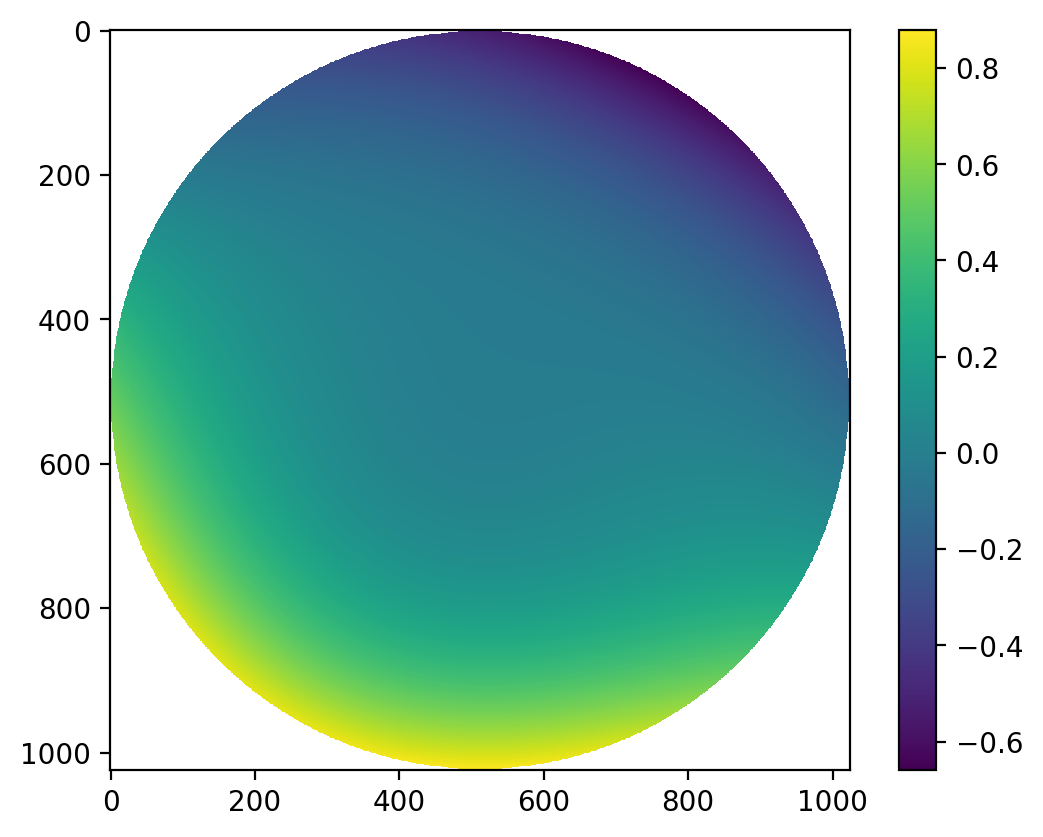

In [ ]:
e = poppy.zernike.decompose_opd_nonorthonormal_basis(WFf0)
plt.imshow(poppy.zernike.compose_opd_from_basis(e, npix=1024))
plt.colorbar()

In [ ]:
def psf_from_wf(wf, nx=1024, pad_factor=2):
    
    #WFf0 = wf.filled(fill_value=0)
    wfarr = wf
    pad_size = nx*pad_factor
    expwf = np.zeros((pad_size, pad_size), dtype=np.complex128)
    start = pad_size//2-nx//2
    stop = pad_size//2+nx//2
    expwf[start:stop, start:stop][~wfarr.mask] = \
    np.exp(2j*np.pi*wfarr[~wfarr.mask])
    psf = np.abs(np.fft.fftshift(np.fft.fft2(expwf)))**2
    psf = psf / np.max(psf)

    return psf